In [1]:
import torch
import torchvision
from torch import nn, optim, distributions
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

rcParams['figure.figsize'] = 8, 8
plt.ion()

# Training configuration
BATCH_SIZE = 1024      # How many data points to process at once
EPOCHS = 50            # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
OUTPUT_DIM = 28 * 28
HIDDEN_DIM = 1024
N_COUPLE_LAYERS = 14

# Visualization settings
SAVE_PLT_INTERVAL = 1  # How often to save plots

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Using device: {device}")


Using device: cuda


In [2]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [3]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE, 
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE, 
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 1024
Training batches: 59
Test batches: 10


In [4]:
class CouplingLayer(nn.Module):
    """
    A coupling layer that transforms data using neural networks.
    
    The key idea: 
    - Split input x into two parts using a mask
    - Transform one part based on the other part
    - Combine them back together
    """
    
    def __init__(self, input_dim, output_dim, hid_dim, mask):
        super().__init__()

        # The mask determines which dimensions to transform
        # mask = [0, 1] means: don't transform dimension 0, transform dimension 1
        self.register_buffer("mask", mask, persistent=False)
        
        # Neural networks to compute scaling (s) and translation (t) factors
        # These networks take the "untransformed" part and predict how to transform the other part
        
        # Scaling network (s): predicts how much to scale each dimension
        self.s_fc1 = nn.Linear(input_dim, hid_dim)
        self.s_fc2 = nn.Linear(hid_dim, hid_dim)
        self.s_fc3 = nn.Linear(hid_dim, output_dim)
        
        # Translation network (t): predicts how much to shift each dimension
        self.t_fc1 = nn.Linear(input_dim, hid_dim)
        self.t_fc2 = nn.Linear(hid_dim, hid_dim)
        self.t_fc3 = nn.Linear(hid_dim, output_dim)

    def forward(self, x):
        """
        Transform x to y using the coupling layer.
        Returns: y (transformed data) and log_det_jacobian (for computing likelihood)
        """
        # Apply mask to get the "untransformed" part
        x_m = x * self.mask
        
        # Compute scaling and translation factors from the untransformed part
        s_out = torch.tanh(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(x_m))))))
        t_out = self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(x_m)))))
        
        # Apply the transformation: y = x_m + (1-mask) * (x * exp(s) + t)
        # This means: keep the masked part unchanged, transform the unmasked part
        y = x_m + (1 - self.mask) * (x * torch.exp(s_out) + t_out)
        
        # Compute log determinant of Jacobian (needed for likelihood computation)
        log_det_jacobian = s_out.sum(dim=1)
        
        return y, log_det_jacobian

    def backward(self, y):
        """
        Reverse transformation: convert y back to x.
        This is what makes the flow invertible!
        """
        # Apply mask to get the "untransformed" part
        y_m = y * self.mask
        
        # Compute scaling and translation factors
        s_out = torch.tanh(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(y_m))))))
        
        t_out = self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(y_m)))))
        
        # Reverse the transformation: x = y_m + (1-mask) * (y - t) * exp(-s)
        x = y_m + (1 - self.mask) * (y - t_out) * torch.exp(-s_out)
        
        return x


In [5]:
class RealNVP(nn.Module):
    """
    RealNVP (Real Non-Volume Preserving) flow model.
    
    This model chains multiple coupling layers together to create a powerful
    transformation from our complex data distribution to a simple Gaussian.
    """
    
    def __init__(self, input_dim, output_dim, hid_dim, mask, n_layers=6):
        super().__init__()
        
        # We need at least 2 layers to ensure all dimensions can be transformed
        assert n_layers >= 2, 'Number of coupling layers should be >= 2'
        
        # Create a list of coupling layers
        self.modules = []
        
        # First layer uses the given mask
        self.modules.append(CouplingLayer(input_dim, output_dim, hid_dim, mask))
        
        # Middle layers alternate the mask pattern
        # This ensures all dimensions get transformed
        for _ in range(n_layers - 2):
            mask = 1 - mask  # Flip the mask
            self.modules.append(CouplingLayer(input_dim, output_dim, hid_dim, mask))
        
        # Last layer uses the opposite mask
        self.modules.append(CouplingLayer(input_dim, output_dim, hid_dim, 1 - mask))
        
        # Convert to PyTorch ModuleList for proper parameter tracking
        self.module_list = nn.ModuleList(self.modules)
        
    def forward(self, x):
        """
        Transform data from complex distribution to simple Gaussian.
        Returns: z (transformed data) and sum of log determinants
        """
        ldj_sum = 0  # Sum of log determinant of Jacobian
        
        # Pass data through each coupling layer
        for module in self.module_list:
            x, ldj = module(x)
            ldj_sum += ldj
            
        return x, ldj_sum

    def backward(self, z):
        """
        Reverse transformation: convert from Gaussian back to complex distribution.
        This is how we generate new samples!
        """
        # Pass through layers in reverse order
        for module in reversed(self.module_list):
            z = module.backward(z)
            
        return z


Mask pattern:


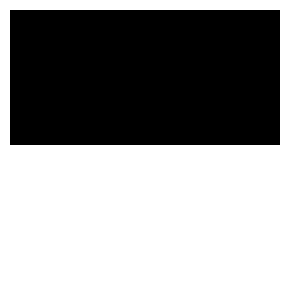


Model parameters: 74,397,120
Learning rate: 1e-4
Target distribution: 2D Gaussian (mean=0, std=1)

Model architecture:
RealNVP(
  (module_list): ModuleList(
    (0-13): 14 x CouplingLayer(
      (s_fc1): Linear(in_features=784, out_features=1024, bias=True)
      (s_fc2): Linear(in_features=1024, out_features=1024, bias=True)
      (s_fc3): Linear(in_features=1024, out_features=784, bias=True)
      (t_fc1): Linear(in_features=784, out_features=1024, bias=True)
      (t_fc2): Linear(in_features=1024, out_features=1024, bias=True)
      (t_fc3): Linear(in_features=1024, out_features=784, bias=True)
    )
  )
)


In [6]:
# Create the mask for our coupling layers
# mask = [0, 1] means: don't transform x-coordinate, transform y-coordinate
mask = torch.from_numpy(np.concat([np.zeros([14 * 28]), np.ones(14 * 28)]).astype(np.float32))

# Create our RealNVP model
model = RealNVP(INPUT_DIM, OUTPUT_DIM, HIDDEN_DIM, mask, N_COUPLE_LAYERS).to(device)

# Set up the optimizer (Adam is a popular choice for neural networks)
optimizer = optim.Adam(model.parameters(), lr=1e-5)

# This is what we want our complex data to look like after transformation
prior_z = distributions.MultivariateNormal(torch.zeros(INPUT_DIM, device=device), torch.eye(INPUT_DIM, device=device))

print("Mask pattern:")

plt.figure(figsize=(3, 3))
plt.imshow(np.reshape(mask, [28, 28]), cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Learning rate: 1e-4")
print(f"Target distribution: 2D Gaussian (mean=0, std=1)")

# Let's see what our model looks like
print("\nModel architecture:")
print(model)


In [7]:
def train(epoch):
    """
    Train the model for one epoch.
    
    The training process:
    1. Transform our complex data to simple Gaussian space
    2. Compute the likelihood of the transformed data
    3. Minimize negative log-likelihood (maximize likelihood)
    """
    model.train()  # Set model to training mode
    train_loss = 0
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device, non_blocking=True)
        # Clear gradients from previous iteration
        optimizer.zero_grad()
        
        # Transform data to Gaussian space
        z, log_det_j_sum = model(data)
        
        # Compute loss: negative log-likelihood
        # We want the transformed data to look like our target Gaussian
        loss = -(prior_z.log_prob(z) + log_det_j_sum).mean()
        
        # Backpropagate gradients
        loss.backward()
        
        # Update model parameters
        optimizer.step()
        
        # Track loss for monitoring
        cur_loss = loss.item()
        train_loss += cur_loss
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), cur_loss / len(data)))

    # Print average loss for this epoch
    avg_loss = train_loss / len(train_loader.dataset)
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, avg_loss))
    
    return avg_loss


In [8]:
def test(epoch):
    """
    Test the model and create visualizations.
    
    This function:
    1. Evaluates the model on test data
    2. Transforms test data to Gaussian space
    3. Creates visualizations to see how well the transformation works
    """
    model.eval()  # Set model to evaluation mode
    test_loss = 0
    
    # Arrays to store all test data for visualization
    x_all = np.array([[]]).reshape(0, INPUT_DIM)  # Original data
    z_all = np.array([[]]).reshape(0, INPUT_DIM)  # Transformed data
    
    with torch.no_grad():  # Don't compute gradients during testing
        for batch_idx, (data, labels) in enumerate(test_loader):
            data = data.to(device, non_blocking=True)
            # Transform data to Gaussian space
            z, log_det_j_sum = model(data)
            
            # Compute test loss
            cur_loss = -(prior_z.log_prob(z) + log_det_j_sum).mean().item()
            test_loss += cur_loss
            
            # Store data for visualization
            x_all = np.concatenate((x_all, data.cpu().numpy()))
            z_all = np.concatenate((z_all, z.cpu().numpy()))

    pca = pca_fit(x_all)
    subfig_plot(1, pca, x_all, -25, 25, -25, 25, 'Input', 'b')
    subfig_plot(2, pca, z_all, -25, 25, -25, 25, 'Output', 'b')
    
    # Print test loss
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))
    
    return test_loss


In [9]:
def sample(epoch):
    """
    Generate new samples by sampling from Gaussian and transforming back.
    
    This is the magic of normalizing flows - we can generate new data
    that follows the same distribution as our training data!
    """
    model.eval()
    
    with torch.no_grad():
        # Sample 1000 points from our target Gaussian distribution
        z = prior_z.sample((1000,))
        
        # Transform back to our complex distribution
        x = model.backward(z)
        
        # Convert to numpy for visualization
        z = z.cpu().numpy()
        x = x.cpu().numpy()
        
        # Create visualizations
        pca = pca_fit(x)
        subfig_plot(3, pca, z, -25, 25, -25, 25, 'Input', 'r')
        subfig_plot(4, pca, x, -25, 25, -25, 25, 'Output', 'r')
        
        # Save plots periodically
        if epoch % SAVE_PLT_INTERVAL == 0:
            if not os.path.exists('results'):
                os.makedirs('results')
            plt.savefig('results/' + 'result_' + str(epoch) + '.png')
            print(f"💾 Saved plot: results/result_{epoch}.png")

def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),  # Середнє = 0, стандартне відхилення = 1
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

def subfig_plot(location, pca, data, x_start, x_end, y_start, y_end, title, color):
    """
    Helper function to create subplots for visualization.
    """

    if location == 1:
        plt.clf()  # Clear the figure for the first subplot


    data_transformed = pca.transform(data)
    
    plt.subplot(2, 2, location)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c=color, s=1)
    plt.xlim(x_start, x_end)
    plt.ylim(y_start, y_end)
    plt.title(title)
    plt.pause(1e-2)  # Small pause for interactive plotting


🎯 Starting training...

📊 Epoch 1/50
------------------------------


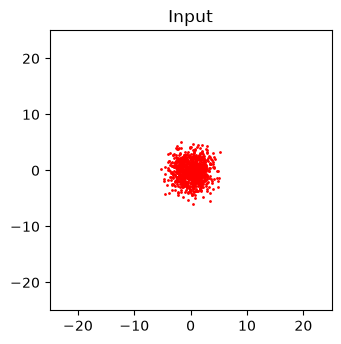

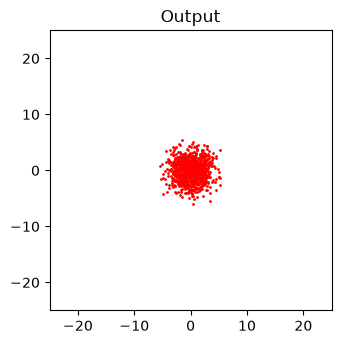

💾 Saved plot: results/result_1.png
Train Epoch: 1 [0/60000 (0%)]	Loss: 0.748343
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.312650
====> Epoch: 1 Average loss: 0.5345


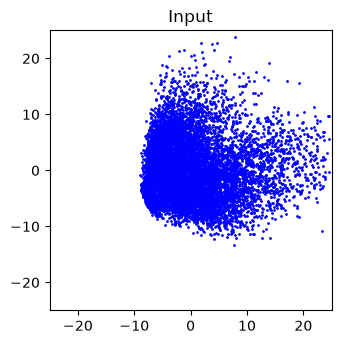

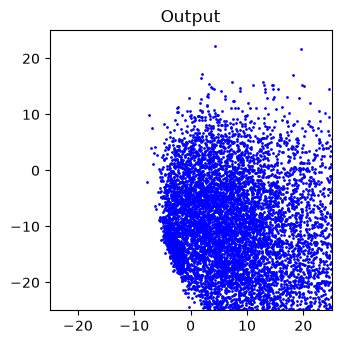

====> Test set loss: 0.0534
📈 Epoch 1 Summary:
   Train Loss: 0.5345
   Test Loss:  0.0534

📊 Epoch 2/50
------------------------------


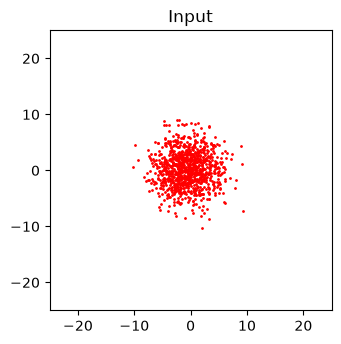

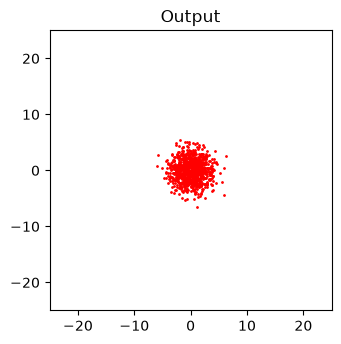

💾 Saved plot: results/result_2.png
Train Epoch: 2 [0/60000 (0%)]	Loss: 0.059644
Train Epoch: 2 [51200/60000 (85%)]	Loss: -2.789438
====> Epoch: 2 Average loss: -1.3996


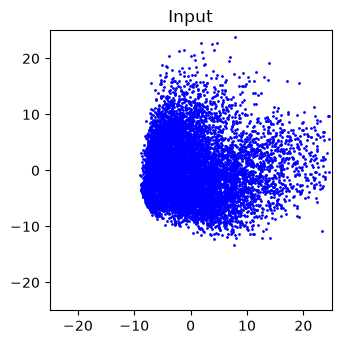

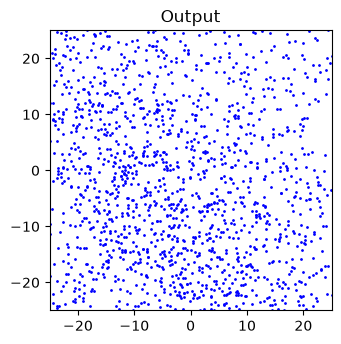

====> Test set loss: -3.6759
📈 Epoch 2 Summary:
   Train Loss: -1.3996
   Test Loss:  -3.6759

📊 Epoch 3/50
------------------------------


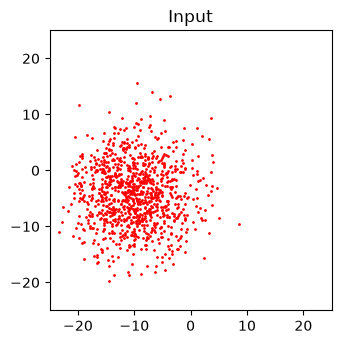

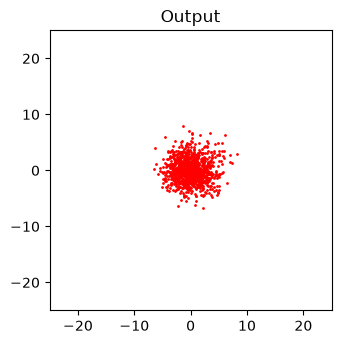

💾 Saved plot: results/result_3.png
Train Epoch: 3 [0/60000 (0%)]	Loss: -3.531244
Train Epoch: 3 [51200/60000 (85%)]	Loss: -5.406418
====> Epoch: 3 Average loss: -4.8309


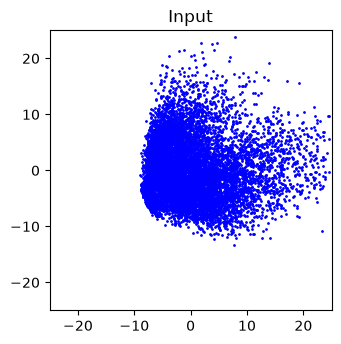

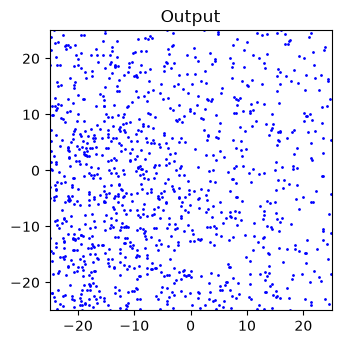

====> Test set loss: -5.6727
📈 Epoch 3 Summary:
   Train Loss: -4.8309
   Test Loss:  -5.6727

📊 Epoch 4/50
------------------------------


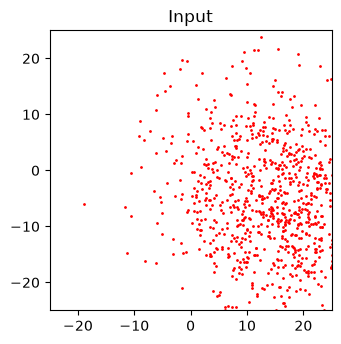

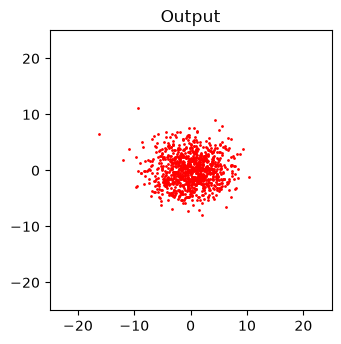

💾 Saved plot: results/result_4.png
Train Epoch: 4 [0/60000 (0%)]	Loss: -5.542306
Train Epoch: 4 [51200/60000 (85%)]	Loss: -5.950483
====> Epoch: 4 Average loss: -5.8476


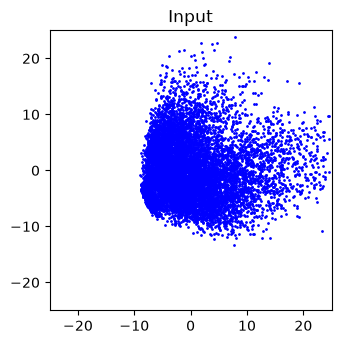

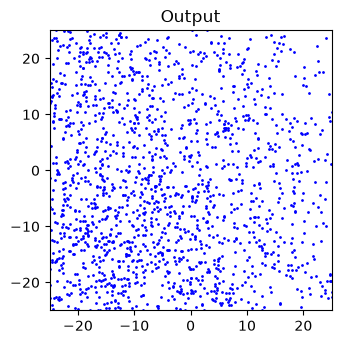

====> Test set loss: -6.1615
📈 Epoch 4 Summary:
   Train Loss: -5.8476
   Test Loss:  -6.1615

📊 Epoch 5/50
------------------------------


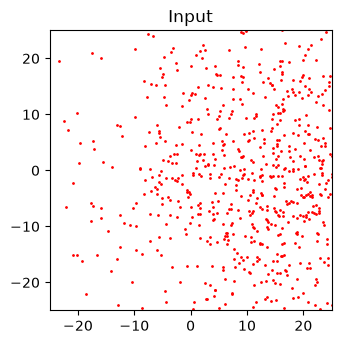

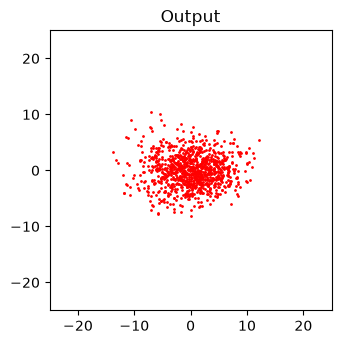

💾 Saved plot: results/result_5.png
Train Epoch: 5 [0/60000 (0%)]	Loss: -6.019952
Train Epoch: 5 [51200/60000 (85%)]	Loss: -6.167911
====> Epoch: 5 Average loss: -6.1449


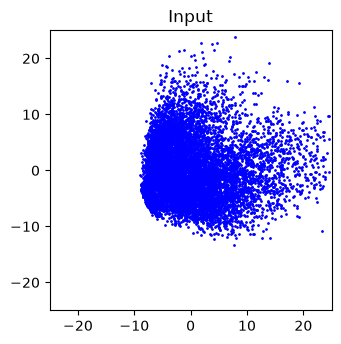

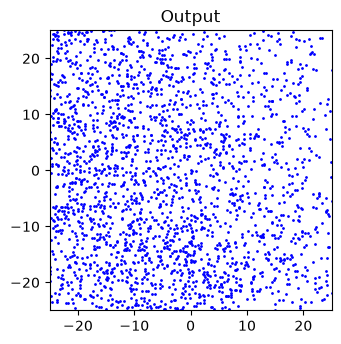

====> Test set loss: -6.3475
📈 Epoch 5 Summary:
   Train Loss: -6.1449
   Test Loss:  -6.3475

📊 Epoch 6/50
------------------------------


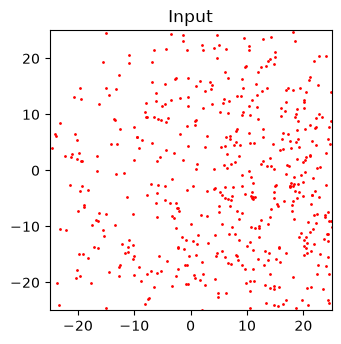

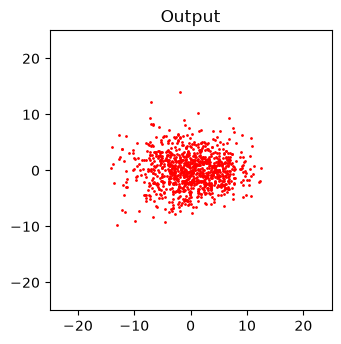

💾 Saved plot: results/result_6.png
Train Epoch: 6 [0/60000 (0%)]	Loss: -6.201274
Train Epoch: 6 [51200/60000 (85%)]	Loss: -6.267934
====> Epoch: 6 Average loss: -6.2905


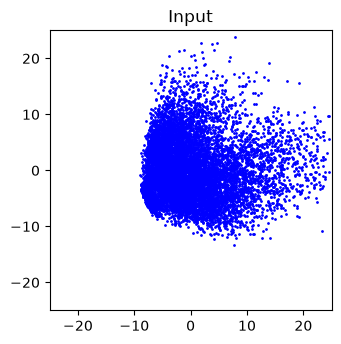

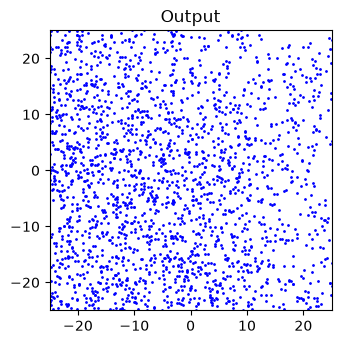

====> Test set loss: -6.4622
📈 Epoch 6 Summary:
   Train Loss: -6.2905
   Test Loss:  -6.4622

📊 Epoch 7/50
------------------------------


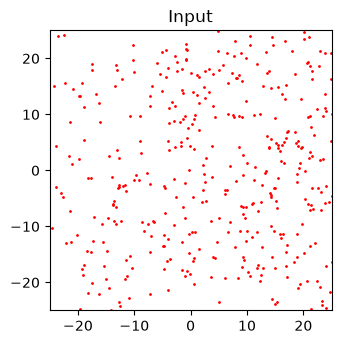

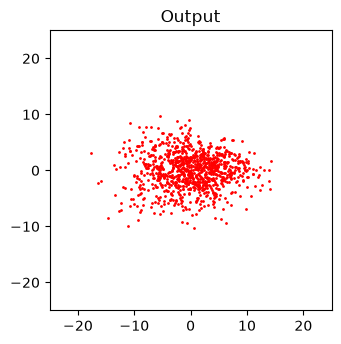

💾 Saved plot: results/result_7.png
Train Epoch: 7 [0/60000 (0%)]	Loss: -6.302155
Train Epoch: 7 [51200/60000 (85%)]	Loss: -6.335260
====> Epoch: 7 Average loss: -6.3961


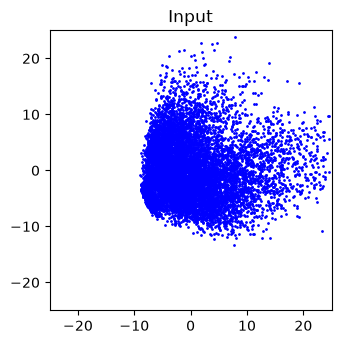

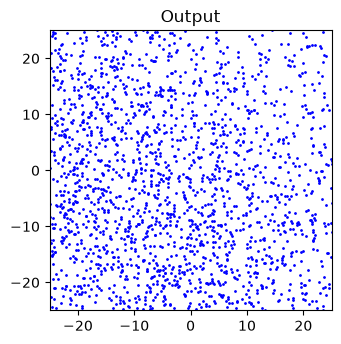

====> Test set loss: -6.5510
📈 Epoch 7 Summary:
   Train Loss: -6.3961
   Test Loss:  -6.5510

📊 Epoch 8/50
------------------------------


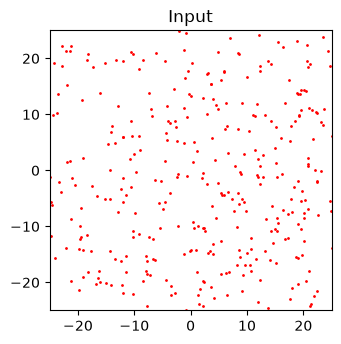

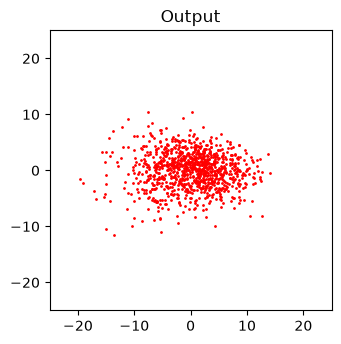

💾 Saved plot: results/result_8.png
Train Epoch: 8 [0/60000 (0%)]	Loss: -6.411768
Train Epoch: 8 [51200/60000 (85%)]	Loss: -6.493946
====> Epoch: 8 Average loss: -6.4823


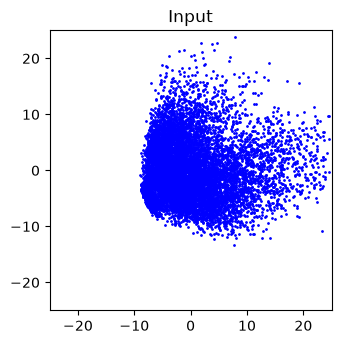

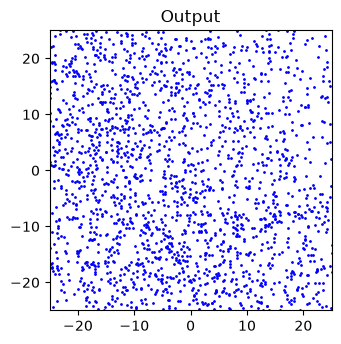

====> Test set loss: -6.6403
📈 Epoch 8 Summary:
   Train Loss: -6.4823
   Test Loss:  -6.6403

📊 Epoch 9/50
------------------------------


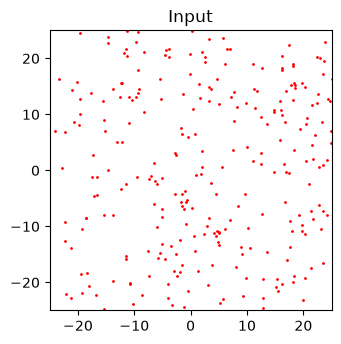

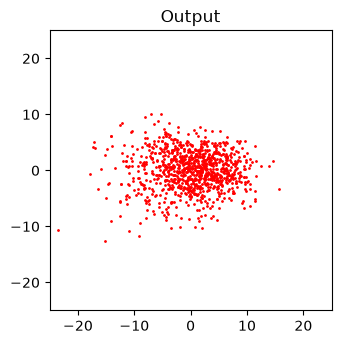

💾 Saved plot: results/result_9.png
Train Epoch: 9 [0/60000 (0%)]	Loss: -6.512304
Train Epoch: 9 [51200/60000 (85%)]	Loss: -6.518531
====> Epoch: 9 Average loss: -6.5581


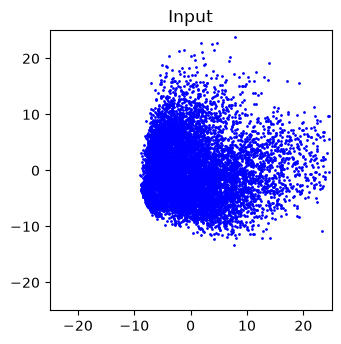

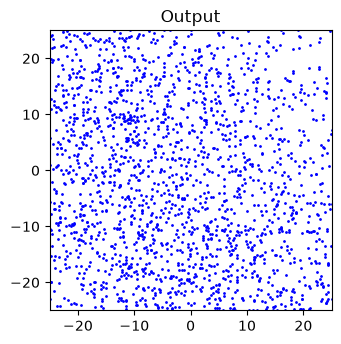

====> Test set loss: -6.7123
📈 Epoch 9 Summary:
   Train Loss: -6.5581
   Test Loss:  -6.7123

📊 Epoch 10/50
------------------------------


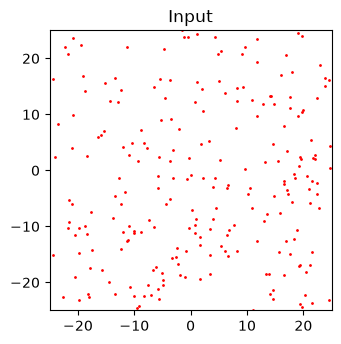

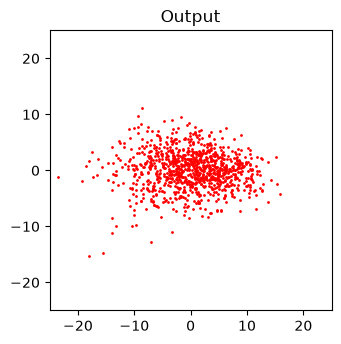

💾 Saved plot: results/result_10.png
Train Epoch: 10 [0/60000 (0%)]	Loss: -6.565499
Train Epoch: 10 [51200/60000 (85%)]	Loss: -6.609637
====> Epoch: 10 Average loss: -6.6264


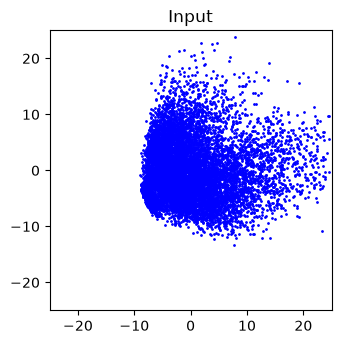

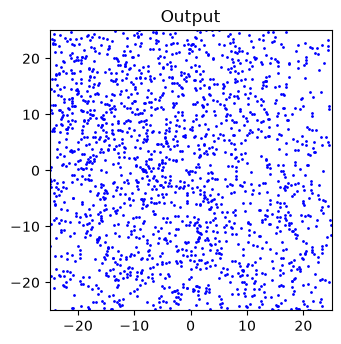

====> Test set loss: -6.7674
📈 Epoch 10 Summary:
   Train Loss: -6.6264
   Test Loss:  -6.7674

📊 Epoch 11/50
------------------------------


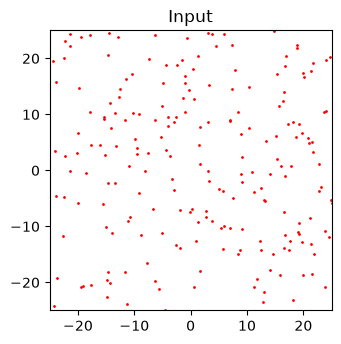

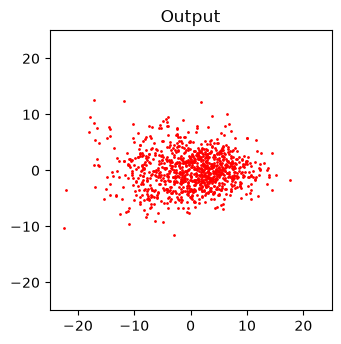

💾 Saved plot: results/result_11.png
Train Epoch: 11 [0/60000 (0%)]	Loss: -6.609904
Train Epoch: 11 [51200/60000 (85%)]	Loss: -6.655861
====> Epoch: 11 Average loss: -6.6866


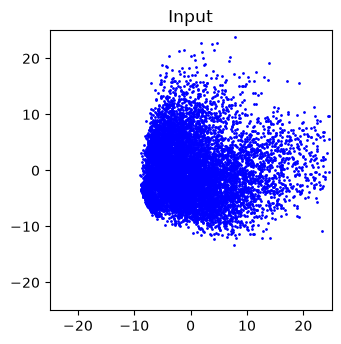

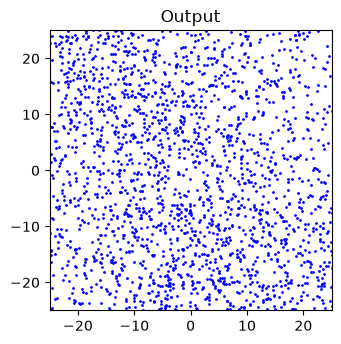

====> Test set loss: -6.8331
📈 Epoch 11 Summary:
   Train Loss: -6.6866
   Test Loss:  -6.8331

📊 Epoch 12/50
------------------------------


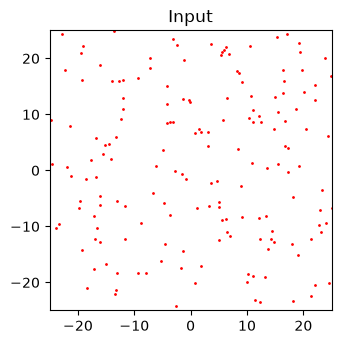

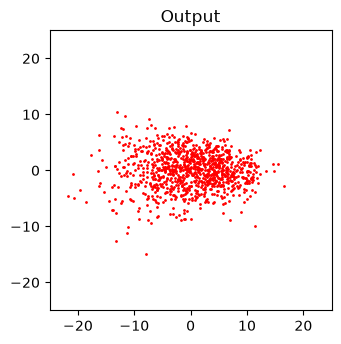

💾 Saved plot: results/result_12.png
Train Epoch: 12 [0/60000 (0%)]	Loss: -6.679639
Train Epoch: 12 [51200/60000 (85%)]	Loss: -6.704124
====> Epoch: 12 Average loss: -6.7400


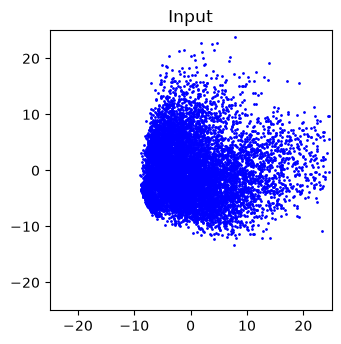

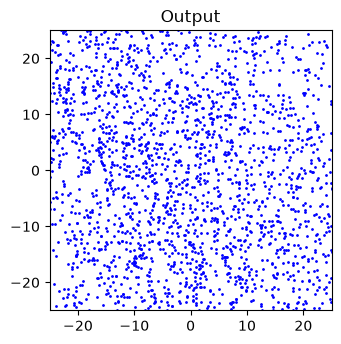

====> Test set loss: -6.8875
📈 Epoch 12 Summary:
   Train Loss: -6.7400
   Test Loss:  -6.8875

📊 Epoch 13/50
------------------------------


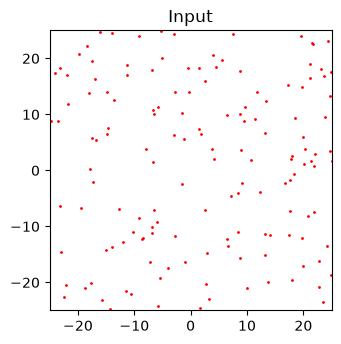

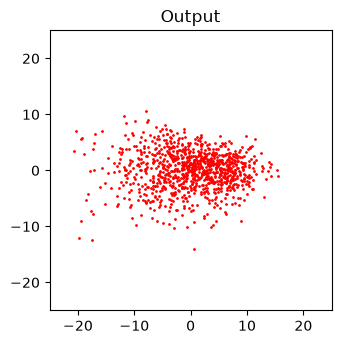

💾 Saved plot: results/result_13.png
Train Epoch: 13 [0/60000 (0%)]	Loss: -6.722693
Train Epoch: 13 [51200/60000 (85%)]	Loss: -6.765860
====> Epoch: 13 Average loss: -6.7921


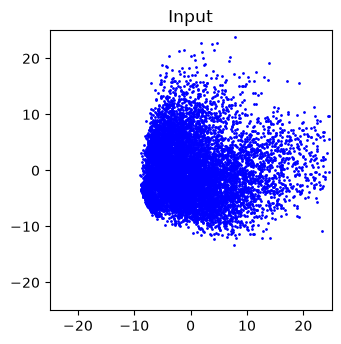

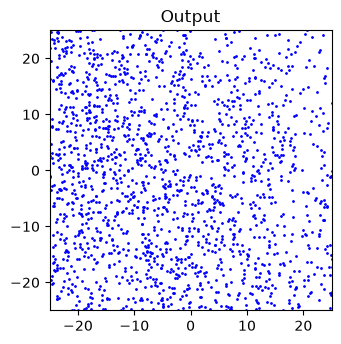

====> Test set loss: -6.9308
📈 Epoch 13 Summary:
   Train Loss: -6.7921
   Test Loss:  -6.9308

📊 Epoch 14/50
------------------------------


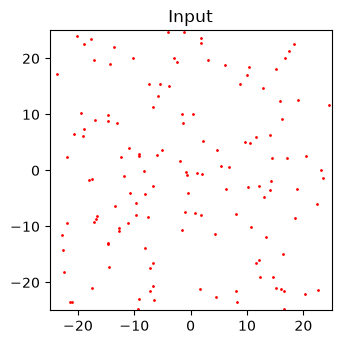

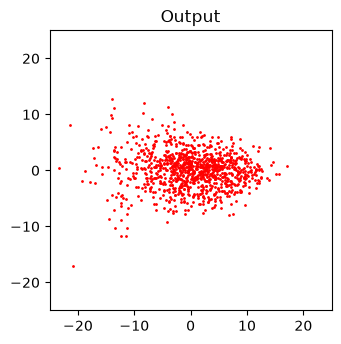

💾 Saved plot: results/result_14.png
Train Epoch: 14 [0/60000 (0%)]	Loss: -6.775694
Train Epoch: 14 [51200/60000 (85%)]	Loss: -6.799575
====> Epoch: 14 Average loss: -6.8368


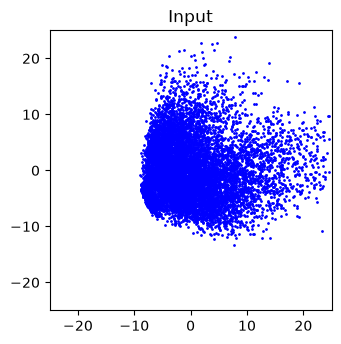

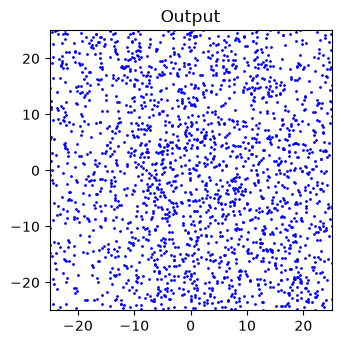

====> Test set loss: -6.9714
📈 Epoch 14 Summary:
   Train Loss: -6.8368
   Test Loss:  -6.9714

📊 Epoch 15/50
------------------------------


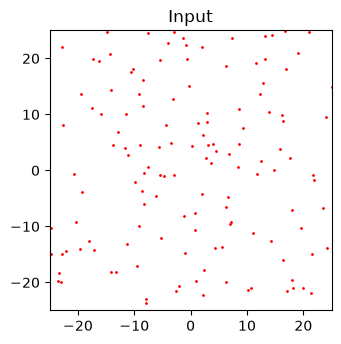

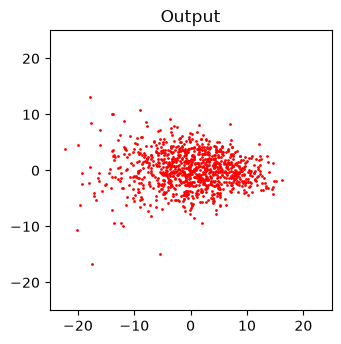

💾 Saved plot: results/result_15.png
Train Epoch: 15 [0/60000 (0%)]	Loss: -6.809429
Train Epoch: 15 [51200/60000 (85%)]	Loss: -6.851143
====> Epoch: 15 Average loss: -6.8800


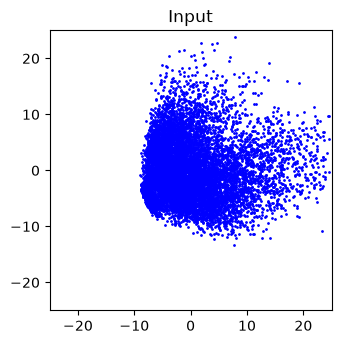

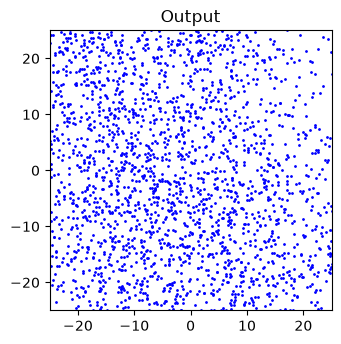

====> Test set loss: -7.0165
📈 Epoch 15 Summary:
   Train Loss: -6.8800
   Test Loss:  -7.0165

📊 Epoch 16/50
------------------------------


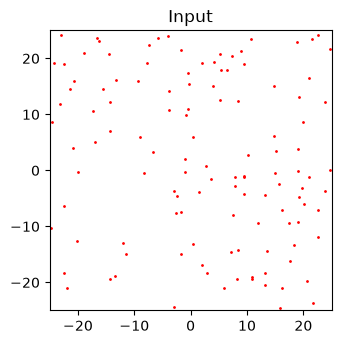

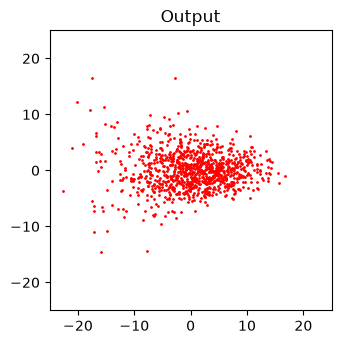

💾 Saved plot: results/result_16.png
Train Epoch: 16 [0/60000 (0%)]	Loss: -6.839539
Train Epoch: 16 [51200/60000 (85%)]	Loss: -6.891603
====> Epoch: 16 Average loss: -6.9199


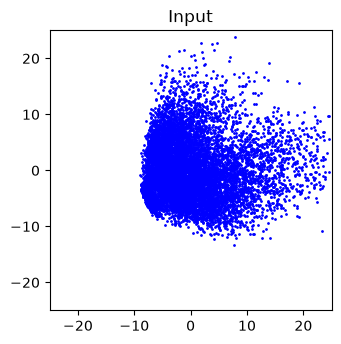

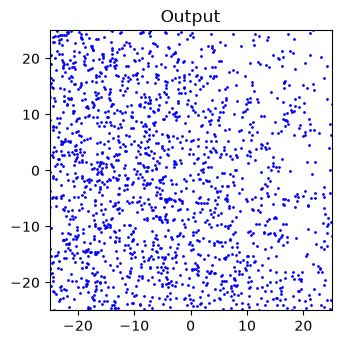

====> Test set loss: -7.0617
📈 Epoch 16 Summary:
   Train Loss: -6.9199
   Test Loss:  -7.0617

📊 Epoch 17/50
------------------------------


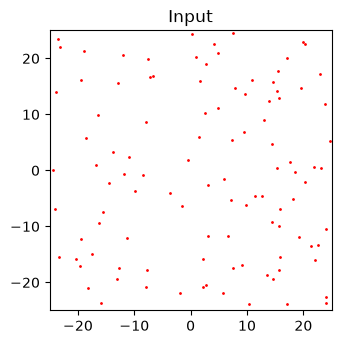

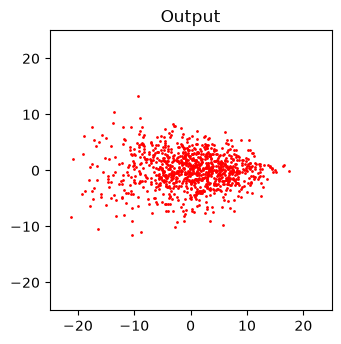

💾 Saved plot: results/result_17.png
Train Epoch: 17 [0/60000 (0%)]	Loss: -6.887897
Train Epoch: 17 [51200/60000 (85%)]	Loss: -6.921577
====> Epoch: 17 Average loss: -6.9573


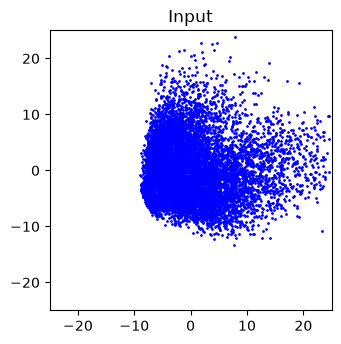

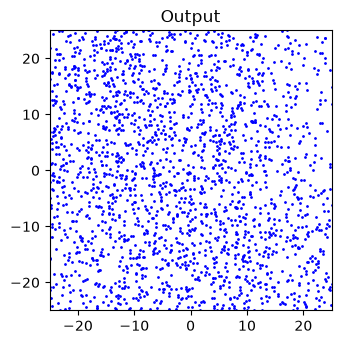

====> Test set loss: -7.0989
📈 Epoch 17 Summary:
   Train Loss: -6.9573
   Test Loss:  -7.0989

📊 Epoch 18/50
------------------------------


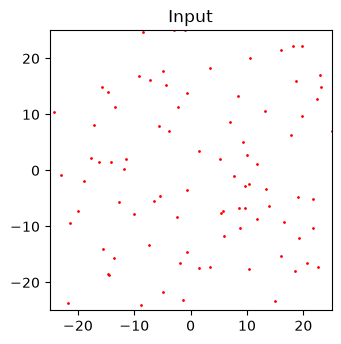

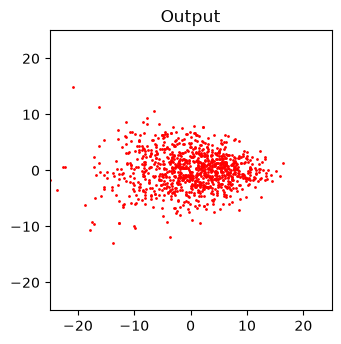

💾 Saved plot: results/result_18.png
Train Epoch: 18 [0/60000 (0%)]	Loss: -6.917854
Train Epoch: 18 [51200/60000 (85%)]	Loss: -6.962776
====> Epoch: 18 Average loss: -6.9943


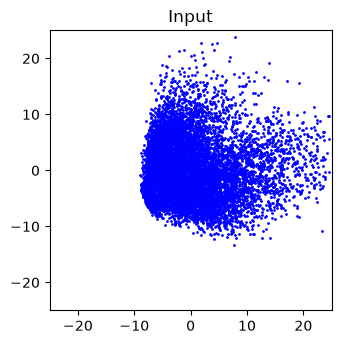

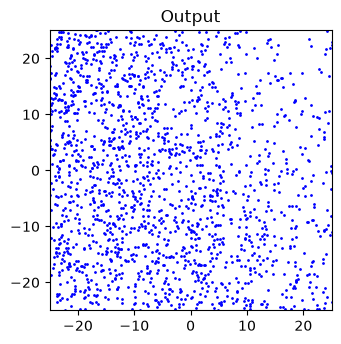

====> Test set loss: -7.1333
📈 Epoch 18 Summary:
   Train Loss: -6.9943
   Test Loss:  -7.1333

📊 Epoch 19/50
------------------------------


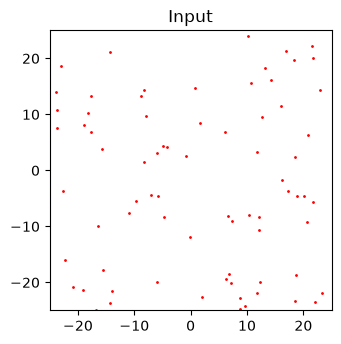

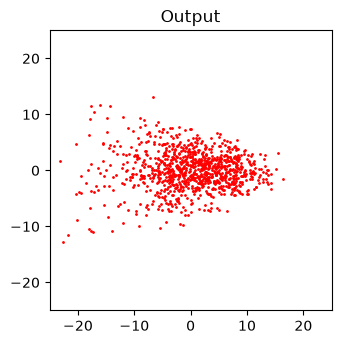

💾 Saved plot: results/result_19.png
Train Epoch: 19 [0/60000 (0%)]	Loss: -6.962622
Train Epoch: 19 [51200/60000 (85%)]	Loss: -6.951163
====> Epoch: 19 Average loss: -7.0271


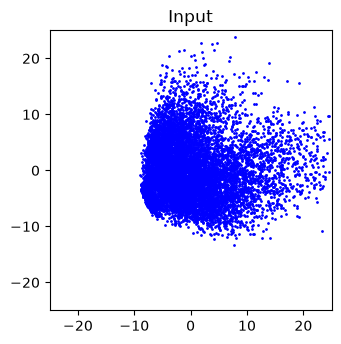

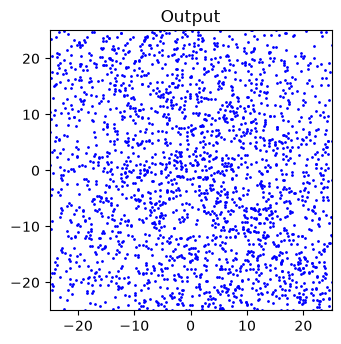

====> Test set loss: -7.1598
📈 Epoch 19 Summary:
   Train Loss: -7.0271
   Test Loss:  -7.1598

📊 Epoch 20/50
------------------------------


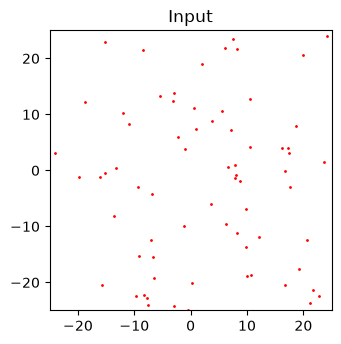

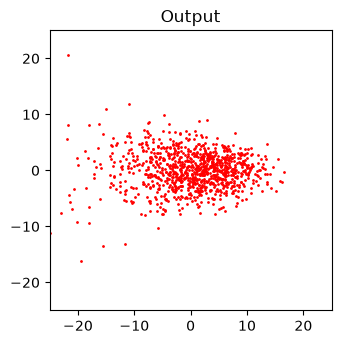

💾 Saved plot: results/result_20.png
Train Epoch: 20 [0/60000 (0%)]	Loss: -6.981921
Train Epoch: 20 [51200/60000 (85%)]	Loss: -7.024504
====> Epoch: 20 Average loss: -7.0606


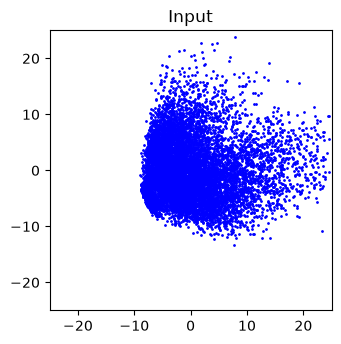

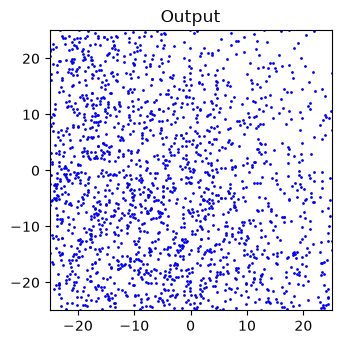

====> Test set loss: -7.1918
📈 Epoch 20 Summary:
   Train Loss: -7.0606
   Test Loss:  -7.1918

📊 Epoch 21/50
------------------------------


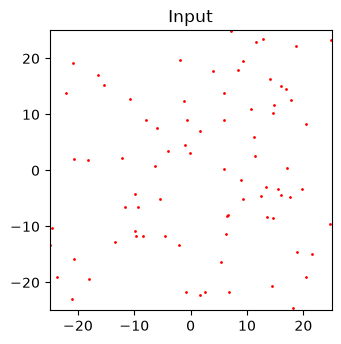

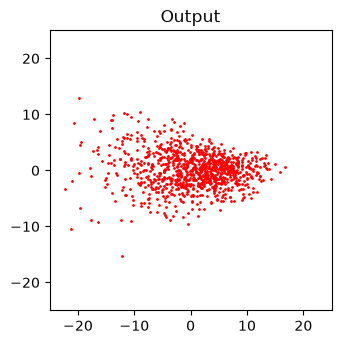

💾 Saved plot: results/result_21.png
Train Epoch: 21 [0/60000 (0%)]	Loss: -7.009621
Train Epoch: 21 [51200/60000 (85%)]	Loss: -7.002539
====> Epoch: 21 Average loss: -7.0663


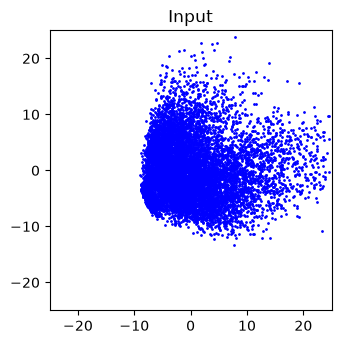

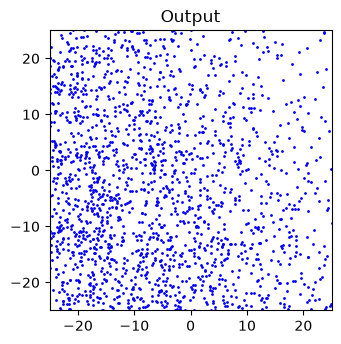

====> Test set loss: -7.2121
📈 Epoch 21 Summary:
   Train Loss: -7.0663
   Test Loss:  -7.2121

📊 Epoch 22/50
------------------------------


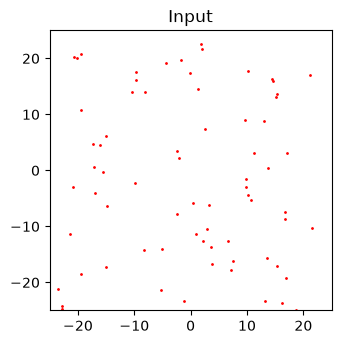

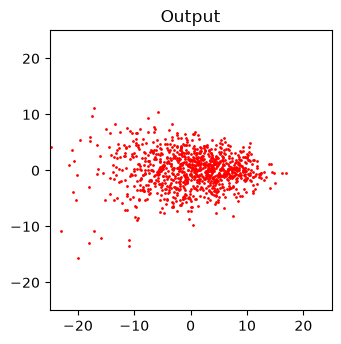

💾 Saved plot: results/result_22.png
Train Epoch: 22 [0/60000 (0%)]	Loss: -7.020165
Train Epoch: 22 [51200/60000 (85%)]	Loss: -7.074484
====> Epoch: 22 Average loss: -7.1154


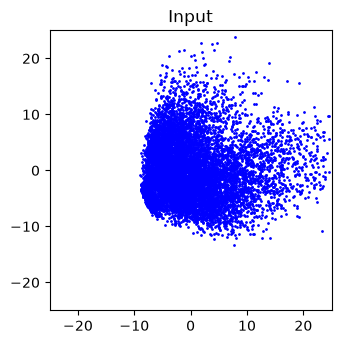

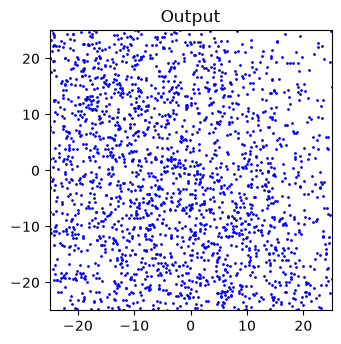

====> Test set loss: -7.2508
📈 Epoch 22 Summary:
   Train Loss: -7.1154
   Test Loss:  -7.2508

📊 Epoch 23/50
------------------------------


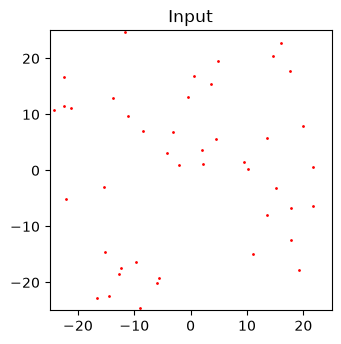

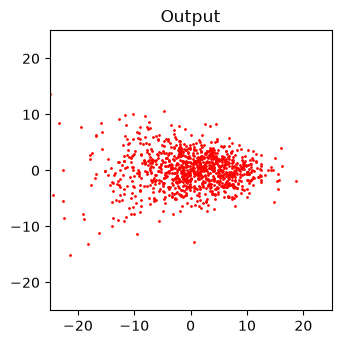

💾 Saved plot: results/result_23.png
Train Epoch: 23 [0/60000 (0%)]	Loss: -7.082945
Train Epoch: 23 [51200/60000 (85%)]	Loss: -7.094701
====> Epoch: 23 Average loss: -7.1457


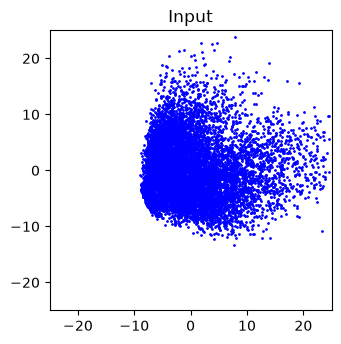

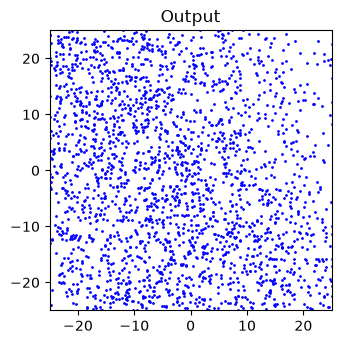

====> Test set loss: -7.2772
📈 Epoch 23 Summary:
   Train Loss: -7.1457
   Test Loss:  -7.2772

📊 Epoch 24/50
------------------------------


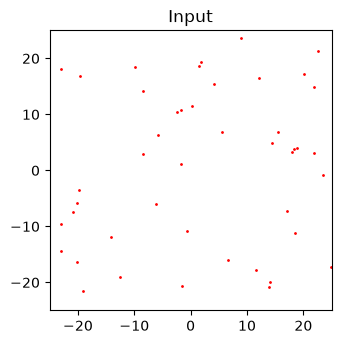

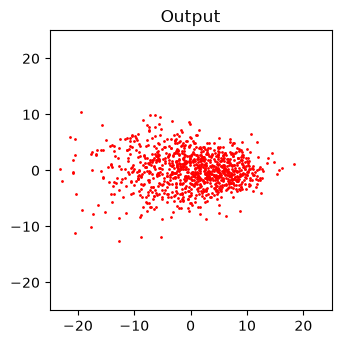

💾 Saved plot: results/result_24.png
Train Epoch: 24 [0/60000 (0%)]	Loss: -7.080267
Train Epoch: 24 [51200/60000 (85%)]	Loss: -7.116966
====> Epoch: 24 Average loss: -7.1694


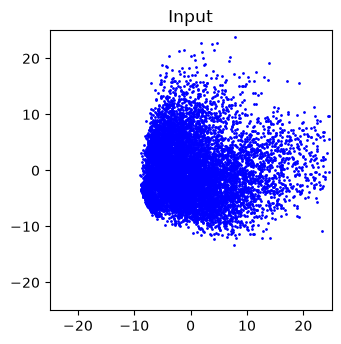

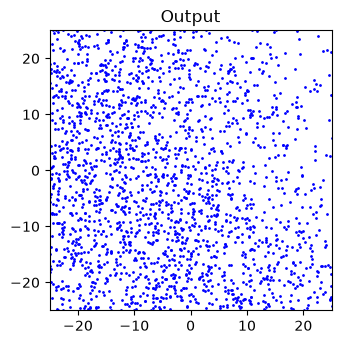

====> Test set loss: -7.3018
📈 Epoch 24 Summary:
   Train Loss: -7.1694
   Test Loss:  -7.3018

📊 Epoch 25/50
------------------------------


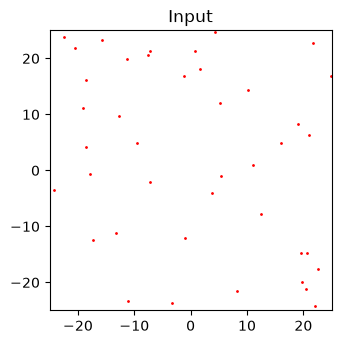

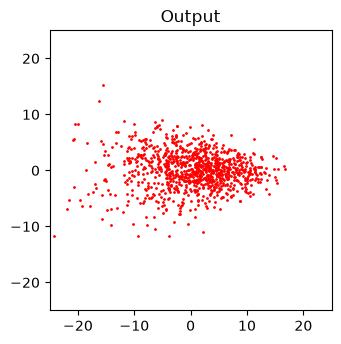

💾 Saved plot: results/result_25.png
Train Epoch: 25 [0/60000 (0%)]	Loss: -7.105650
Train Epoch: 25 [51200/60000 (85%)]	Loss: -7.159718
====> Epoch: 25 Average loss: -7.1932


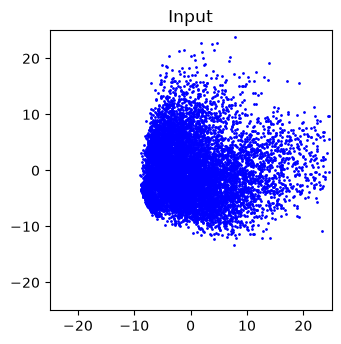

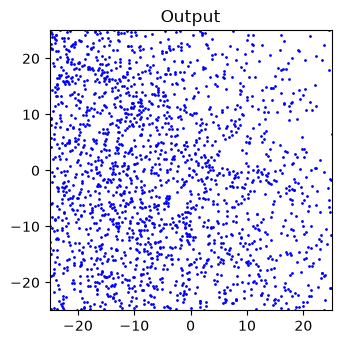

====> Test set loss: -7.3247
📈 Epoch 25 Summary:
   Train Loss: -7.1932
   Test Loss:  -7.3247

📊 Epoch 26/50
------------------------------


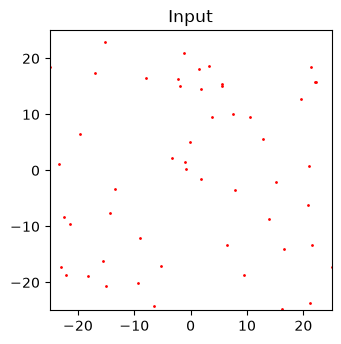

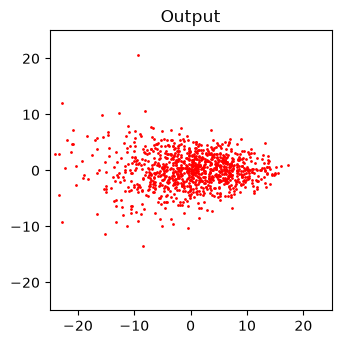

💾 Saved plot: results/result_26.png
Train Epoch: 26 [0/60000 (0%)]	Loss: -7.162237
Train Epoch: 26 [51200/60000 (85%)]	Loss: -7.176665
====> Epoch: 26 Average loss: -7.2162


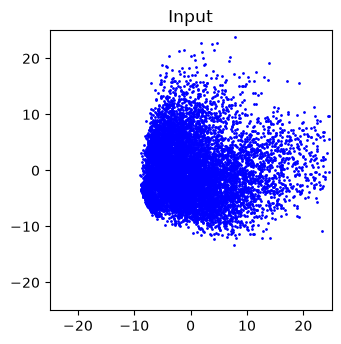

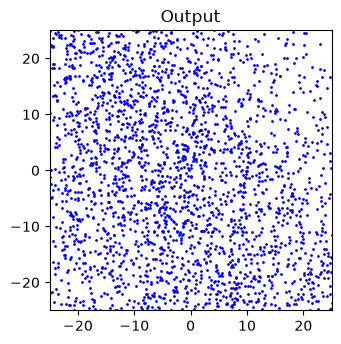

====> Test set loss: -7.3491
📈 Epoch 26 Summary:
   Train Loss: -7.2162
   Test Loss:  -7.3491

📊 Epoch 27/50
------------------------------


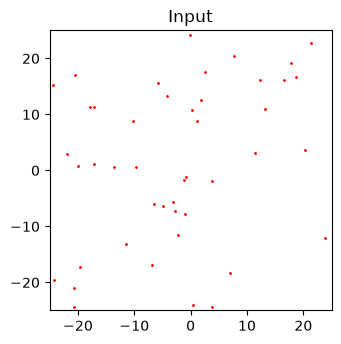

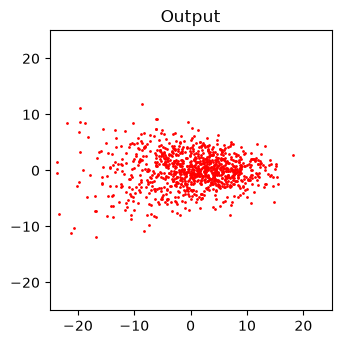

💾 Saved plot: results/result_27.png
Train Epoch: 27 [0/60000 (0%)]	Loss: -7.193668
Train Epoch: 27 [51200/60000 (85%)]	Loss: -7.190828
====> Epoch: 27 Average loss: -7.2397


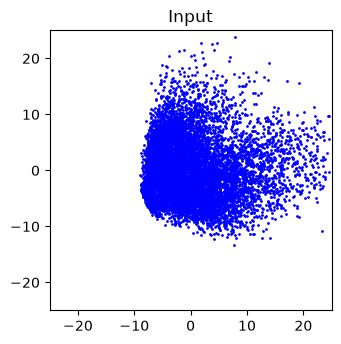

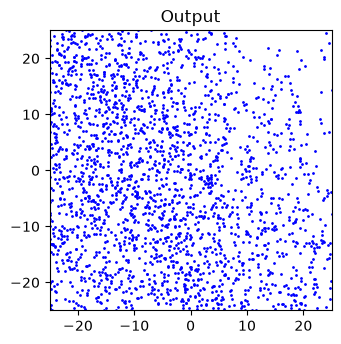

====> Test set loss: -7.3694
📈 Epoch 27 Summary:
   Train Loss: -7.2397
   Test Loss:  -7.3694

📊 Epoch 28/50
------------------------------


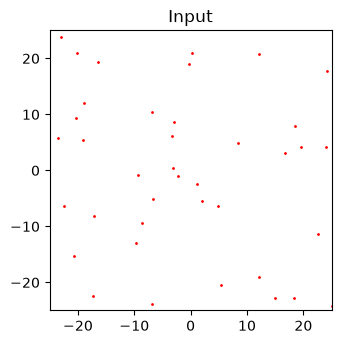

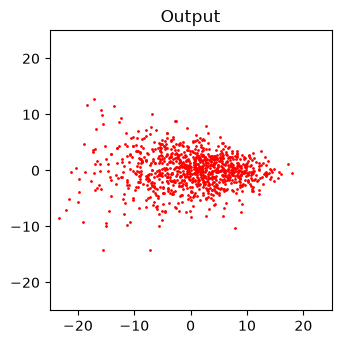

💾 Saved plot: results/result_28.png
Train Epoch: 28 [0/60000 (0%)]	Loss: -7.200948
Train Epoch: 28 [51200/60000 (85%)]	Loss: -7.215332
====> Epoch: 28 Average loss: -7.2310


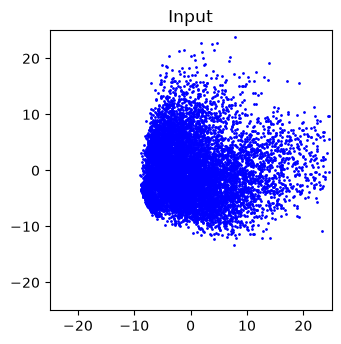

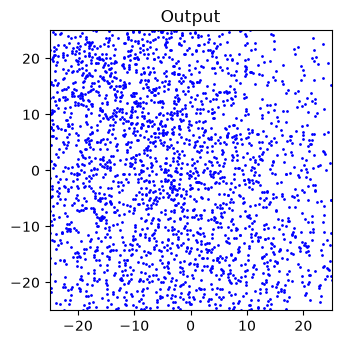

====> Test set loss: -7.3774
📈 Epoch 28 Summary:
   Train Loss: -7.2310
   Test Loss:  -7.3774

📊 Epoch 29/50
------------------------------


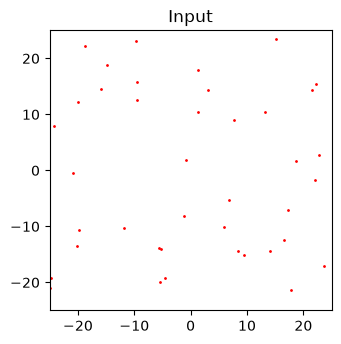

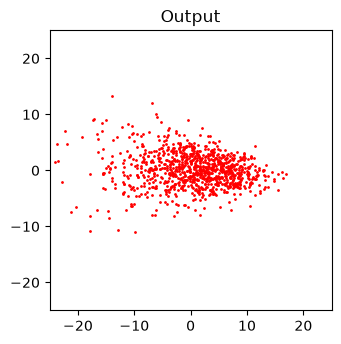

💾 Saved plot: results/result_29.png
Train Epoch: 29 [0/60000 (0%)]	Loss: -7.204779
Train Epoch: 29 [51200/60000 (85%)]	Loss: -7.233240
====> Epoch: 29 Average loss: -7.2789


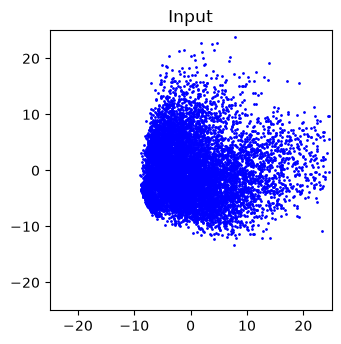

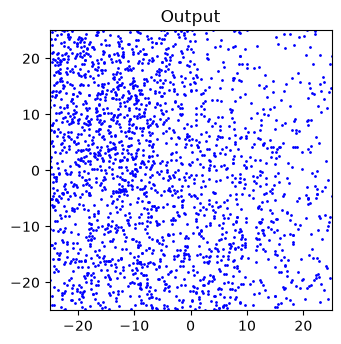

====> Test set loss: -7.4084
📈 Epoch 29 Summary:
   Train Loss: -7.2789
   Test Loss:  -7.4084

📊 Epoch 30/50
------------------------------


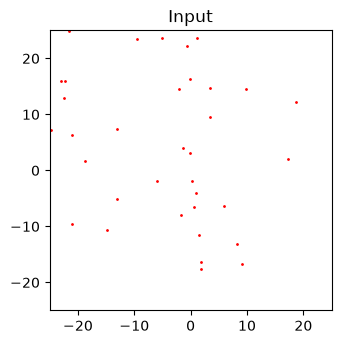

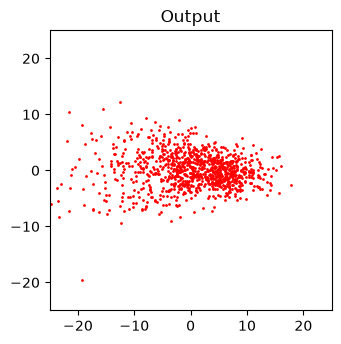

💾 Saved plot: results/result_30.png
Train Epoch: 30 [0/60000 (0%)]	Loss: -7.251398
Train Epoch: 30 [51200/60000 (85%)]	Loss: -7.265049
====> Epoch: 30 Average loss: -7.3013


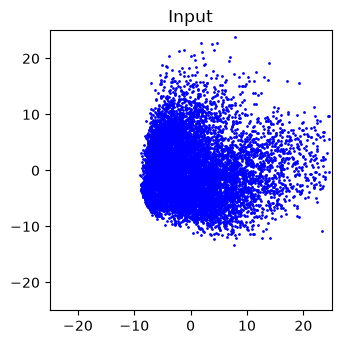

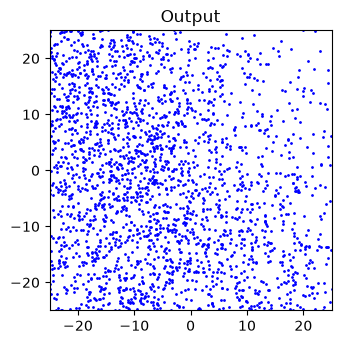

====> Test set loss: -7.4274
📈 Epoch 30 Summary:
   Train Loss: -7.3013
   Test Loss:  -7.4274

📊 Epoch 31/50
------------------------------


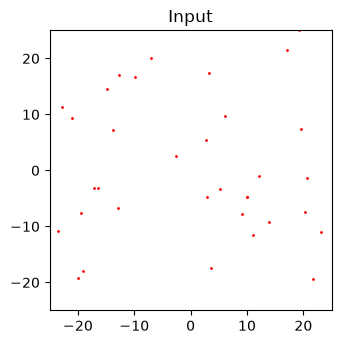

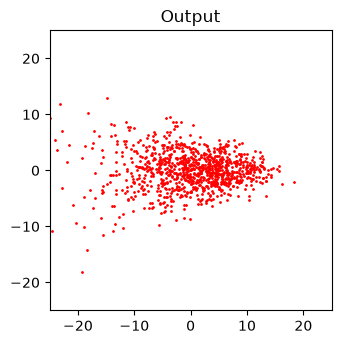

💾 Saved plot: results/result_31.png
Train Epoch: 31 [0/60000 (0%)]	Loss: -7.238848
Train Epoch: 31 [51200/60000 (85%)]	Loss: -7.269737
====> Epoch: 31 Average loss: -7.3203


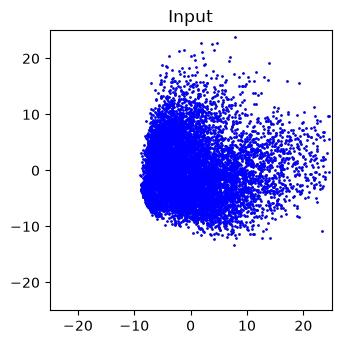

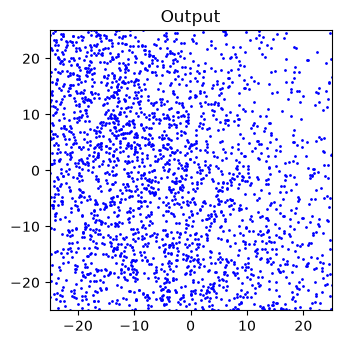

====> Test set loss: -7.4455
📈 Epoch 31 Summary:
   Train Loss: -7.3203
   Test Loss:  -7.4455

📊 Epoch 32/50
------------------------------


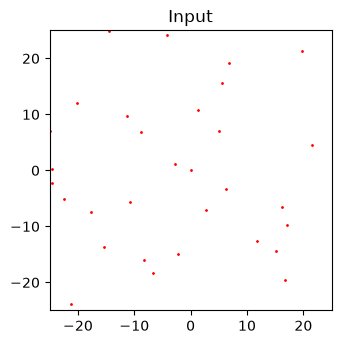

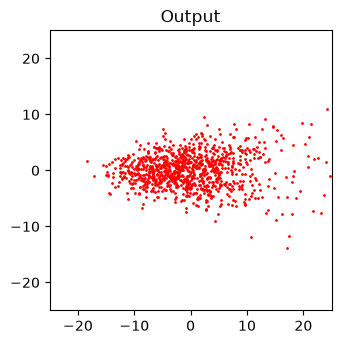

💾 Saved plot: results/result_32.png
Train Epoch: 32 [0/60000 (0%)]	Loss: -7.276649
Train Epoch: 32 [51200/60000 (85%)]	Loss: -7.294445
====> Epoch: 32 Average loss: -7.3336


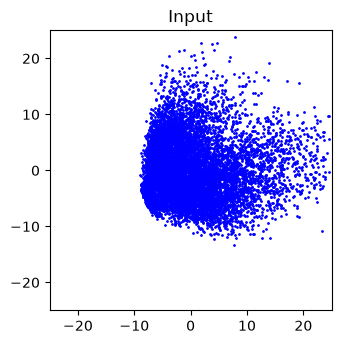

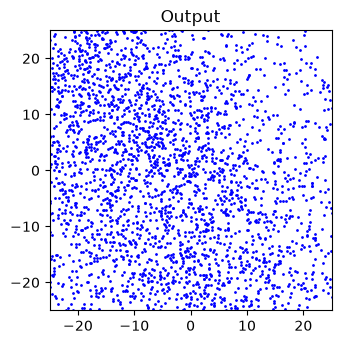

====> Test set loss: -7.4605
📈 Epoch 32 Summary:
   Train Loss: -7.3336
   Test Loss:  -7.4605

📊 Epoch 33/50
------------------------------


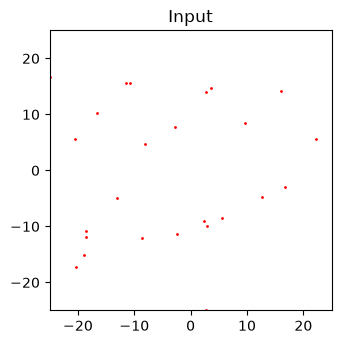

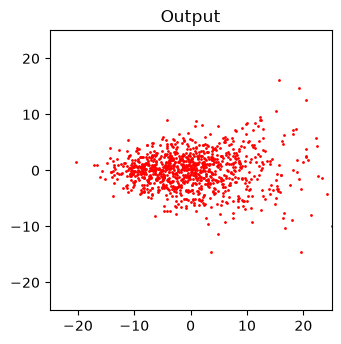

💾 Saved plot: results/result_33.png
Train Epoch: 33 [0/60000 (0%)]	Loss: -7.289145
Train Epoch: 33 [51200/60000 (85%)]	Loss: -7.289272
====> Epoch: 33 Average loss: -7.3550


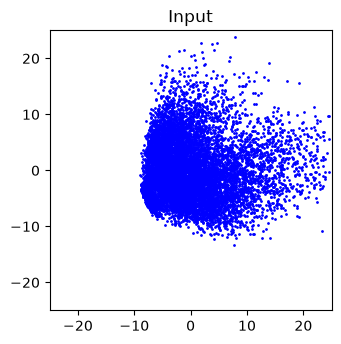

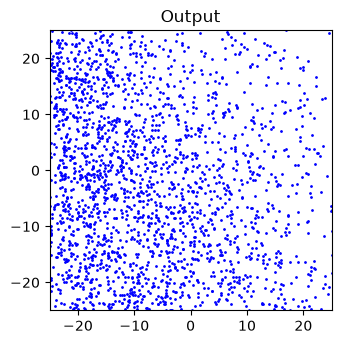

====> Test set loss: -7.4773
📈 Epoch 33 Summary:
   Train Loss: -7.3550
   Test Loss:  -7.4773

📊 Epoch 34/50
------------------------------


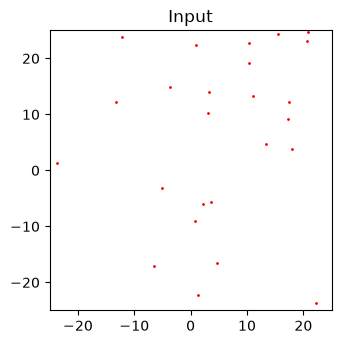

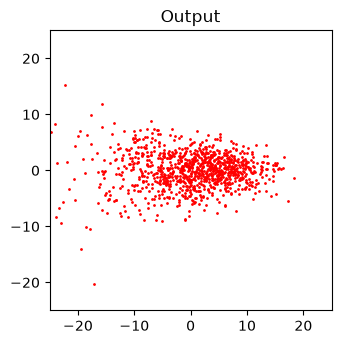

💾 Saved plot: results/result_34.png
Train Epoch: 34 [0/60000 (0%)]	Loss: -7.329221
Train Epoch: 34 [51200/60000 (85%)]	Loss: -7.317950
====> Epoch: 34 Average loss: -7.3714


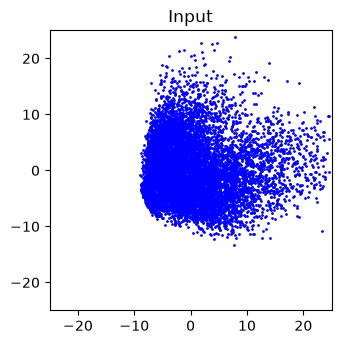

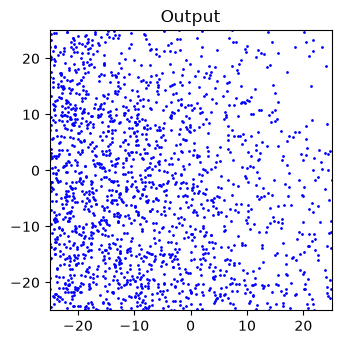

====> Test set loss: -7.4828
📈 Epoch 34 Summary:
   Train Loss: -7.3714
   Test Loss:  -7.4828

📊 Epoch 35/50
------------------------------


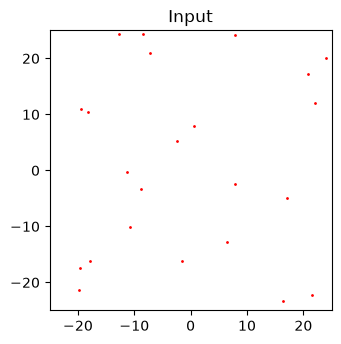

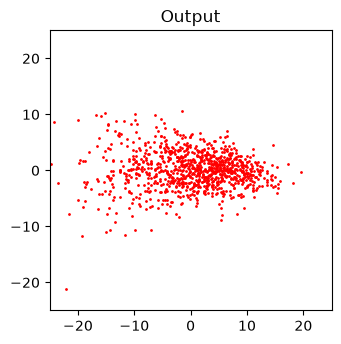

💾 Saved plot: results/result_35.png
Train Epoch: 35 [0/60000 (0%)]	Loss: -7.323328
Train Epoch: 35 [51200/60000 (85%)]	Loss: -7.337680
====> Epoch: 35 Average loss: -7.3868


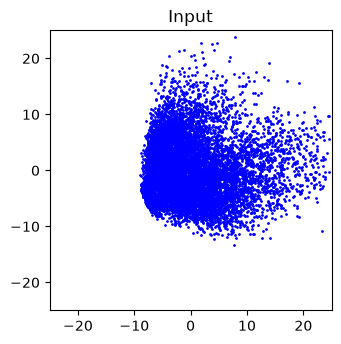

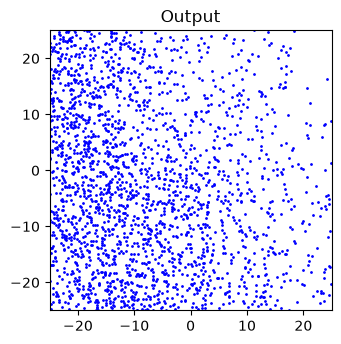

====> Test set loss: -7.5111
📈 Epoch 35 Summary:
   Train Loss: -7.3868
   Test Loss:  -7.5111

📊 Epoch 36/50
------------------------------


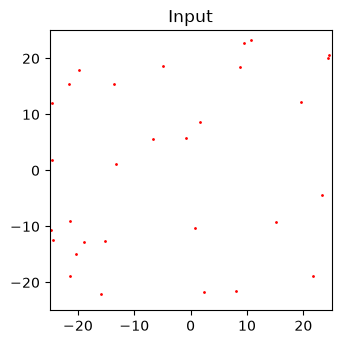

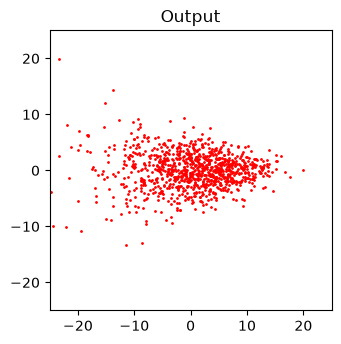

💾 Saved plot: results/result_36.png
Train Epoch: 36 [0/60000 (0%)]	Loss: -7.338988
Train Epoch: 36 [51200/60000 (85%)]	Loss: -7.355386
====> Epoch: 36 Average loss: -7.4046


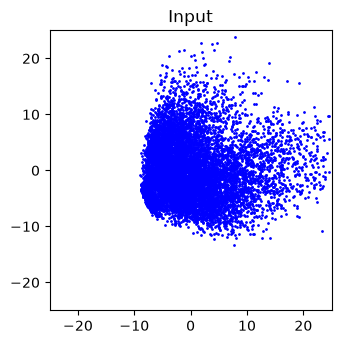

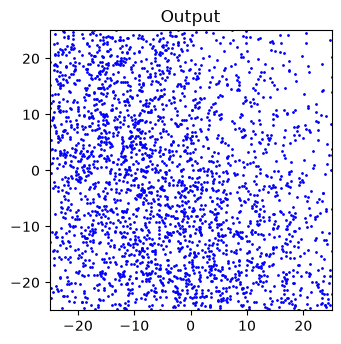

====> Test set loss: -7.5288
📈 Epoch 36 Summary:
   Train Loss: -7.4046
   Test Loss:  -7.5288

📊 Epoch 37/50
------------------------------


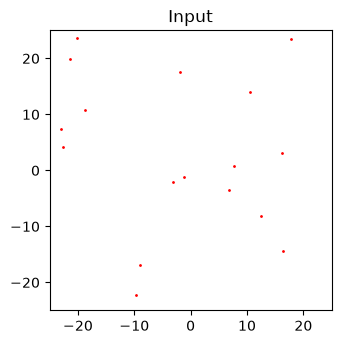

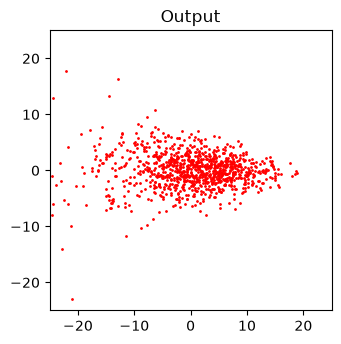

💾 Saved plot: results/result_37.png
Train Epoch: 37 [0/60000 (0%)]	Loss: -7.366951
Train Epoch: 37 [51200/60000 (85%)]	Loss: -7.372111
====> Epoch: 37 Average loss: -7.4161


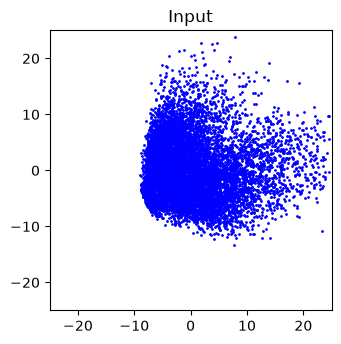

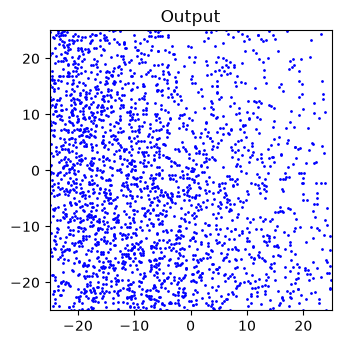

====> Test set loss: -7.5357
📈 Epoch 37 Summary:
   Train Loss: -7.4161
   Test Loss:  -7.5357

📊 Epoch 38/50
------------------------------


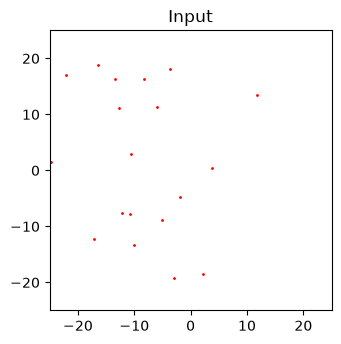

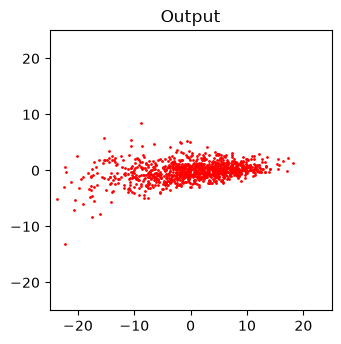

💾 Saved plot: results/result_38.png
Train Epoch: 38 [0/60000 (0%)]	Loss: -7.353491
Train Epoch: 38 [51200/60000 (85%)]	Loss: -7.374834
====> Epoch: 38 Average loss: -7.4340


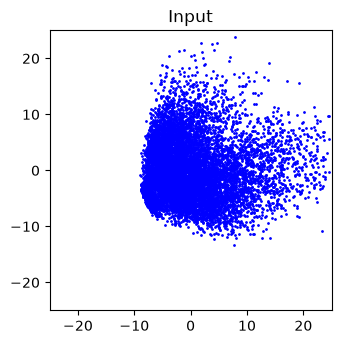

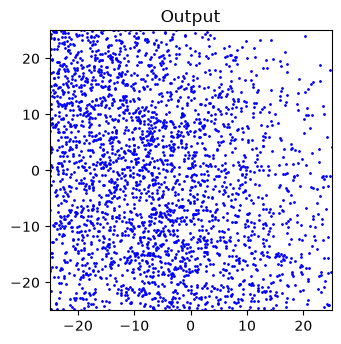

====> Test set loss: -7.5498
📈 Epoch 38 Summary:
   Train Loss: -7.4340
   Test Loss:  -7.5498

📊 Epoch 39/50
------------------------------


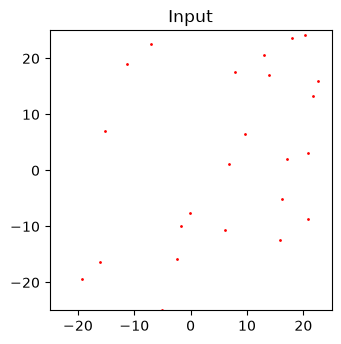

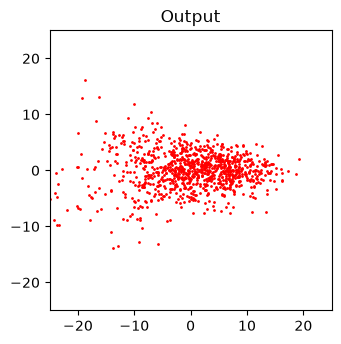

💾 Saved plot: results/result_39.png
Train Epoch: 39 [0/60000 (0%)]	Loss: -7.395677
Train Epoch: 39 [51200/60000 (85%)]	Loss: -7.400720
====> Epoch: 39 Average loss: -7.4464


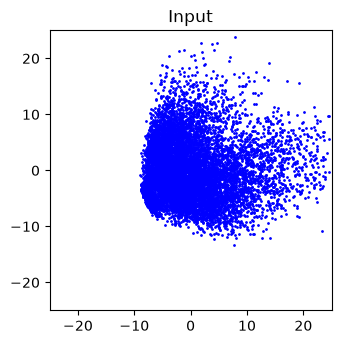

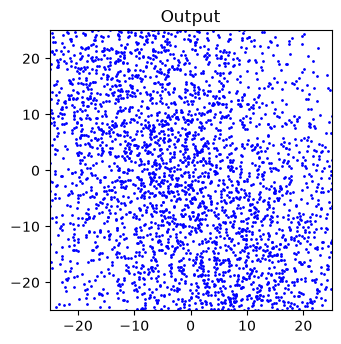

====> Test set loss: -7.5689
📈 Epoch 39 Summary:
   Train Loss: -7.4464
   Test Loss:  -7.5689

📊 Epoch 40/50
------------------------------


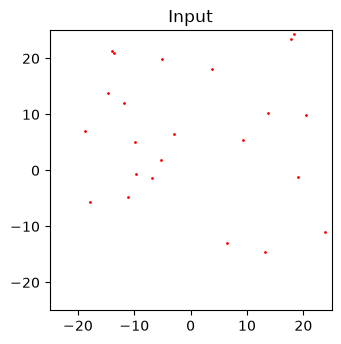

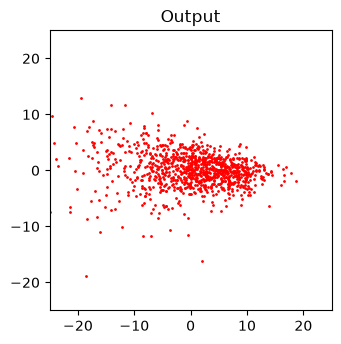

💾 Saved plot: results/result_40.png
Train Epoch: 40 [0/60000 (0%)]	Loss: -7.401063
Train Epoch: 40 [51200/60000 (85%)]	Loss: -7.410876
====> Epoch: 40 Average loss: -7.4604


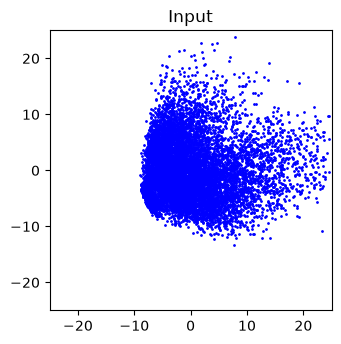

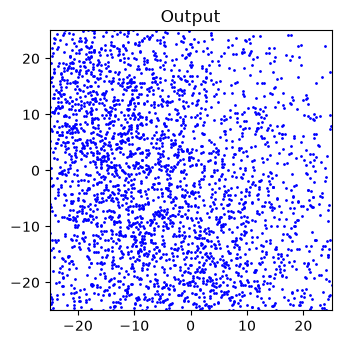

====> Test set loss: -7.5840
📈 Epoch 40 Summary:
   Train Loss: -7.4604
   Test Loss:  -7.5840

📊 Epoch 41/50
------------------------------


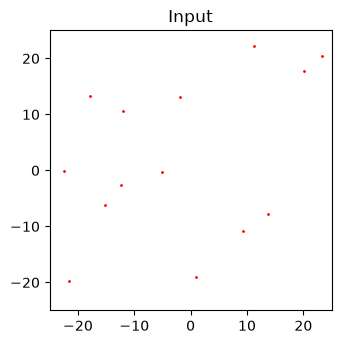

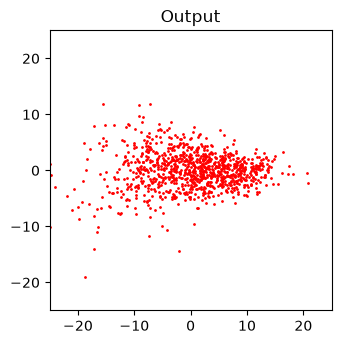

💾 Saved plot: results/result_41.png
Train Epoch: 41 [0/60000 (0%)]	Loss: -7.446133
Train Epoch: 41 [51200/60000 (85%)]	Loss: -7.420935
====> Epoch: 41 Average loss: -7.4786


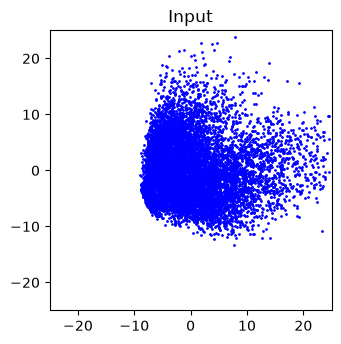

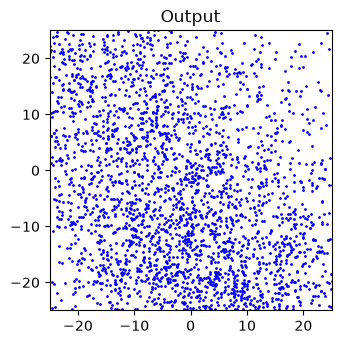

====> Test set loss: -7.5949
📈 Epoch 41 Summary:
   Train Loss: -7.4786
   Test Loss:  -7.5949

📊 Epoch 42/50
------------------------------


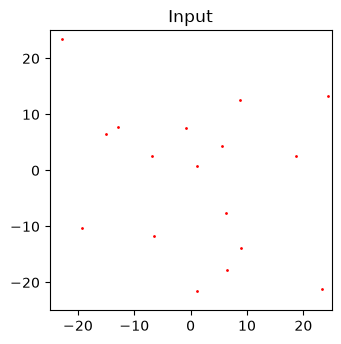

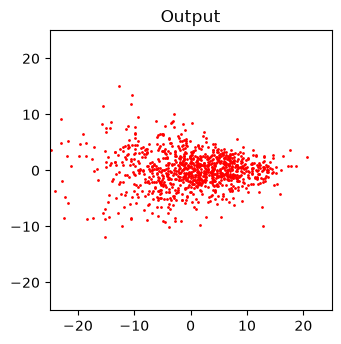

💾 Saved plot: results/result_42.png
Train Epoch: 42 [0/60000 (0%)]	Loss: -7.431719
Train Epoch: 42 [51200/60000 (85%)]	Loss: -7.443991
====> Epoch: 42 Average loss: -7.4894


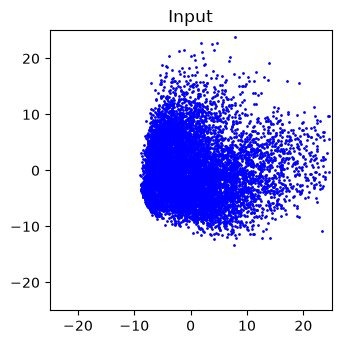

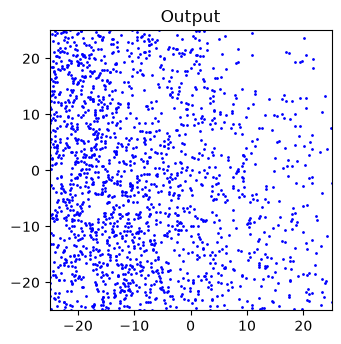

====> Test set loss: -7.5902
📈 Epoch 42 Summary:
   Train Loss: -7.4894
   Test Loss:  -7.5902

📊 Epoch 43/50
------------------------------


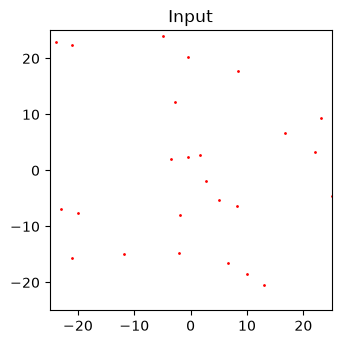

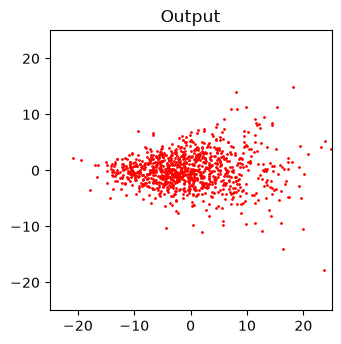

💾 Saved plot: results/result_43.png
Train Epoch: 43 [0/60000 (0%)]	Loss: -7.442398
Train Epoch: 43 [51200/60000 (85%)]	Loss: -7.448936
====> Epoch: 43 Average loss: -7.5026


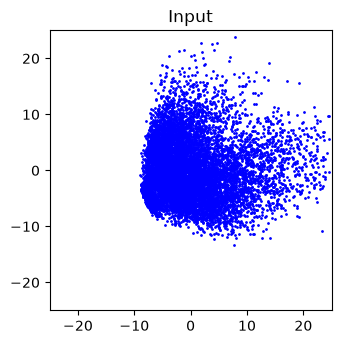

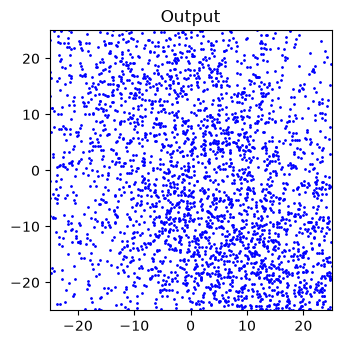

====> Test set loss: -7.6187
📈 Epoch 43 Summary:
   Train Loss: -7.5026
   Test Loss:  -7.6187

📊 Epoch 44/50
------------------------------


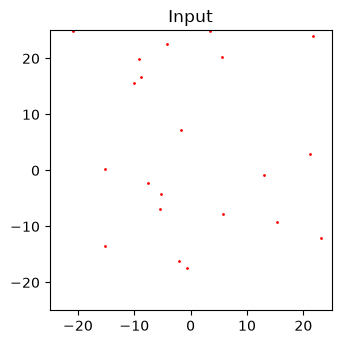

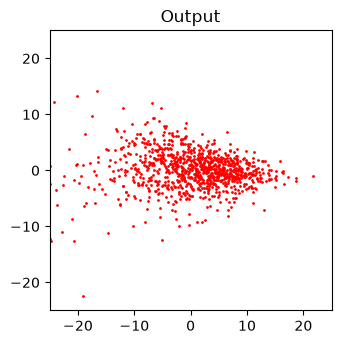

💾 Saved plot: results/result_44.png
Train Epoch: 44 [0/60000 (0%)]	Loss: -7.450599
Train Epoch: 44 [51200/60000 (85%)]	Loss: -7.453001
====> Epoch: 44 Average loss: -7.5135


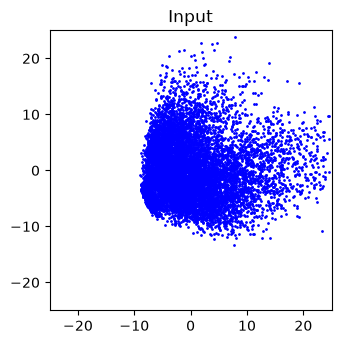

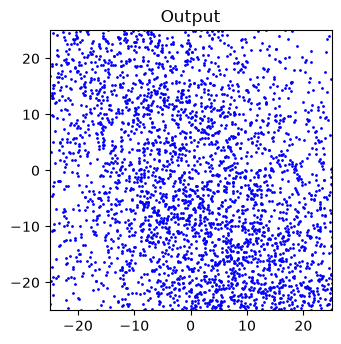

====> Test set loss: -7.6321
📈 Epoch 44 Summary:
   Train Loss: -7.5135
   Test Loss:  -7.6321

📊 Epoch 45/50
------------------------------


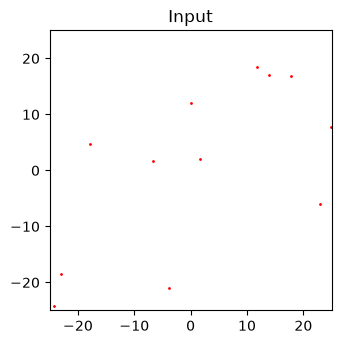

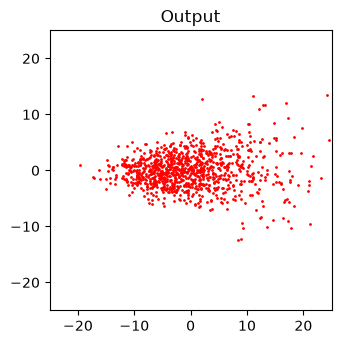

💾 Saved plot: results/result_45.png
Train Epoch: 45 [0/60000 (0%)]	Loss: -7.458476
Train Epoch: 45 [51200/60000 (85%)]	Loss: -7.457618
====> Epoch: 45 Average loss: -7.5227


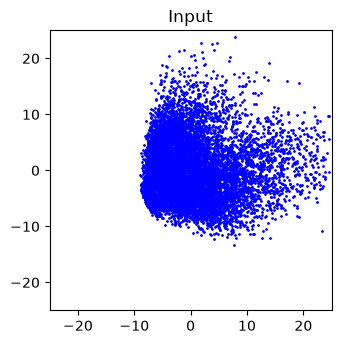

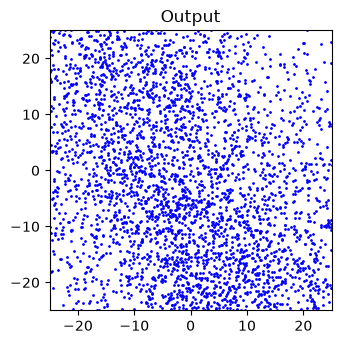

====> Test set loss: -7.6404
📈 Epoch 45 Summary:
   Train Loss: -7.5227
   Test Loss:  -7.6404

📊 Epoch 46/50
------------------------------


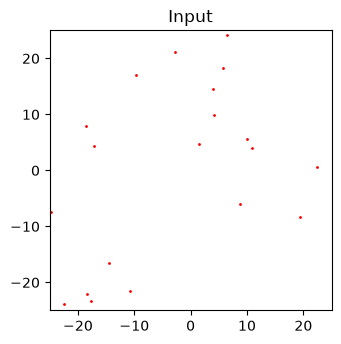

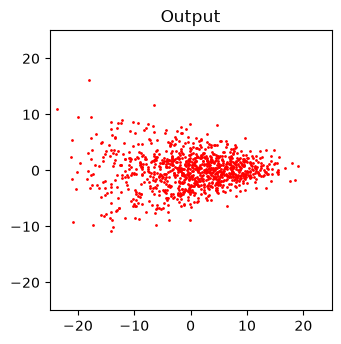

💾 Saved plot: results/result_46.png
Train Epoch: 46 [0/60000 (0%)]	Loss: -7.499177
Train Epoch: 46 [51200/60000 (85%)]	Loss: -7.498263
====> Epoch: 46 Average loss: -7.5402


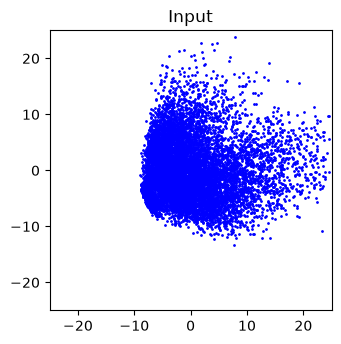

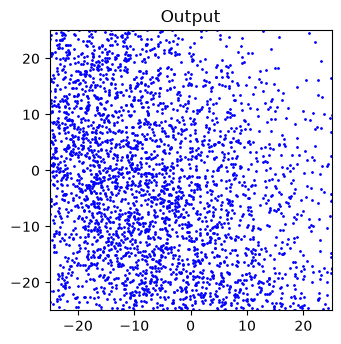

====> Test set loss: -7.6576
📈 Epoch 46 Summary:
   Train Loss: -7.5402
   Test Loss:  -7.6576

📊 Epoch 47/50
------------------------------


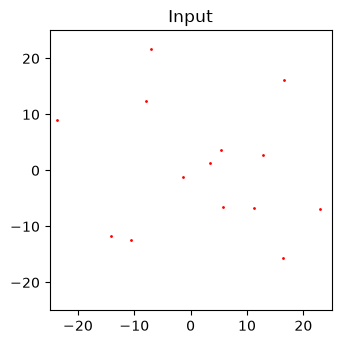

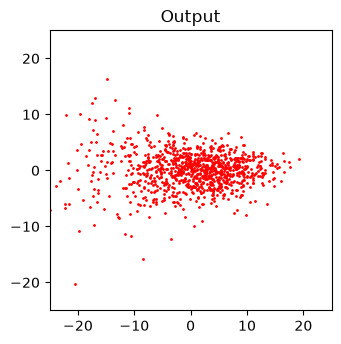

💾 Saved plot: results/result_47.png
Train Epoch: 47 [0/60000 (0%)]	Loss: -7.497516
Train Epoch: 47 [51200/60000 (85%)]	Loss: -7.469187
====> Epoch: 47 Average loss: -7.5494


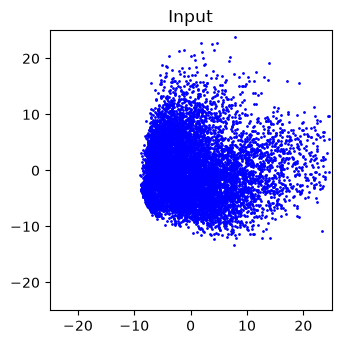

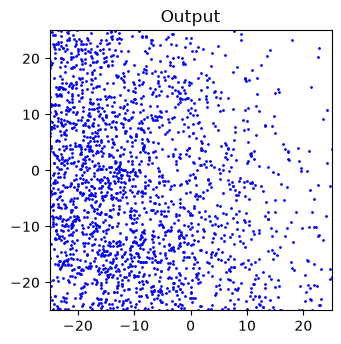

====> Test set loss: -7.6581
📈 Epoch 47 Summary:
   Train Loss: -7.5494
   Test Loss:  -7.6581

📊 Epoch 48/50
------------------------------


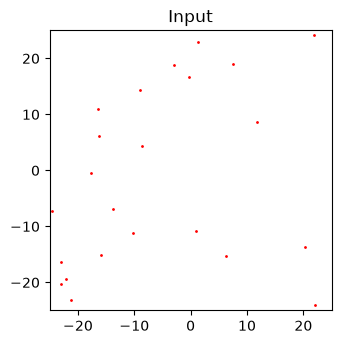

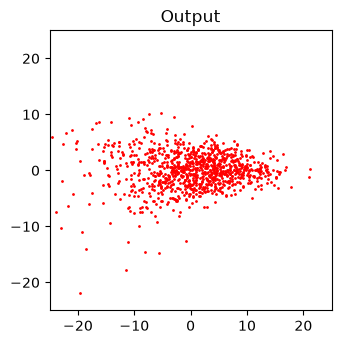

💾 Saved plot: results/result_48.png
Train Epoch: 48 [0/60000 (0%)]	Loss: -7.505807
Train Epoch: 48 [51200/60000 (85%)]	Loss: -7.508188
====> Epoch: 48 Average loss: -7.5415


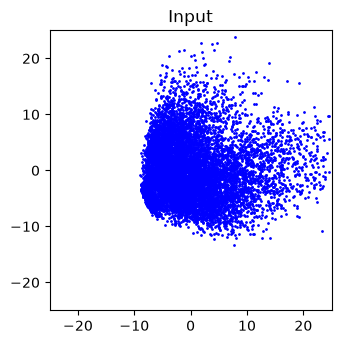

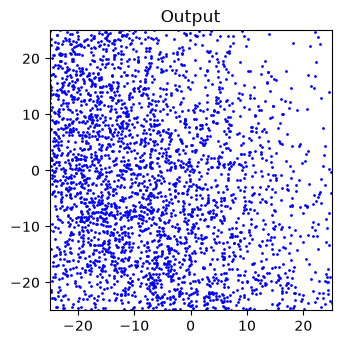

====> Test set loss: -7.6689
📈 Epoch 48 Summary:
   Train Loss: -7.5415
   Test Loss:  -7.6689

📊 Epoch 49/50
------------------------------


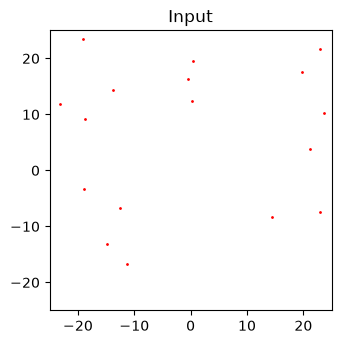

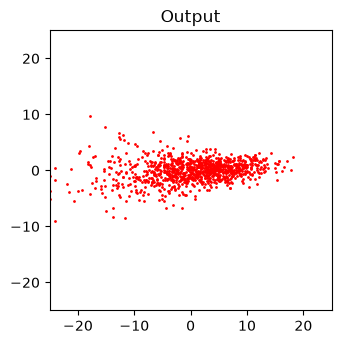

💾 Saved plot: results/result_49.png
Train Epoch: 49 [0/60000 (0%)]	Loss: -7.483456
Train Epoch: 49 [51200/60000 (85%)]	Loss: -7.512858
====> Epoch: 49 Average loss: -7.5751


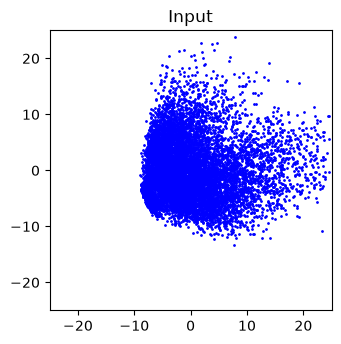

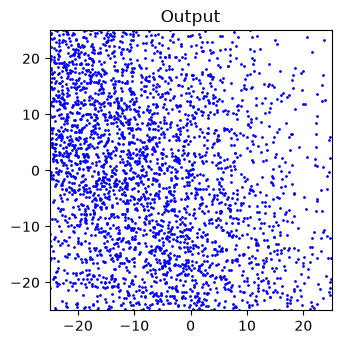

====> Test set loss: -7.6880
📈 Epoch 49 Summary:
   Train Loss: -7.5751
   Test Loss:  -7.6880

📊 Epoch 50/50
------------------------------


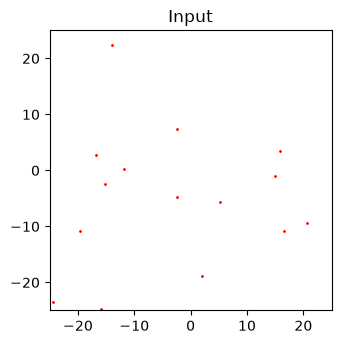

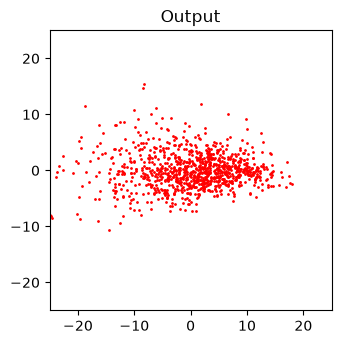

💾 Saved plot: results/result_50.png
Train Epoch: 50 [0/60000 (0%)]	Loss: -7.542106
Train Epoch: 50 [51200/60000 (85%)]	Loss: -7.537410
====> Epoch: 50 Average loss: -7.5871


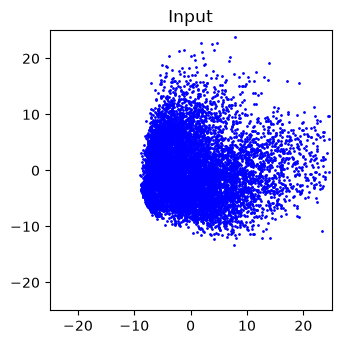

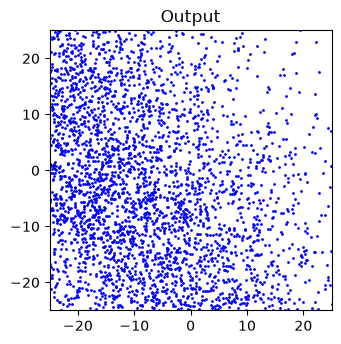

====> Test set loss: -7.6971
📈 Epoch 50 Summary:
   Train Loss: -7.5871
   Test Loss:  -7.6971

🎉 Training completed!
💾 Model saved as 'models/model.pth'


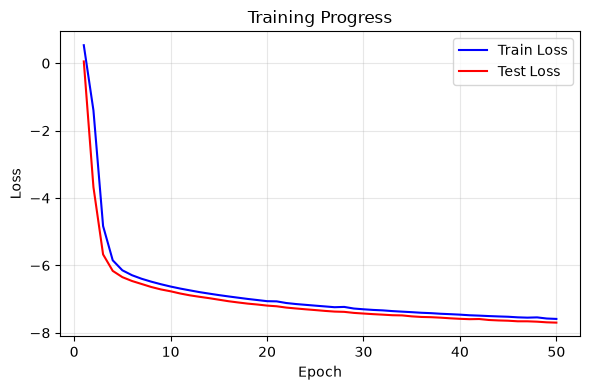

📊 Training progress plotted above!
   Lower loss = better model performance


In [10]:
# Training loop
print("🎯 Starting training...")
print("=" * 50)

# Lists to track training progress
train_losses = []
test_losses = []

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 30)
    
    # Generate samples to see current model performance
    sample(epoch)
    
    # Train the model
    train_loss = train(epoch)
    train_losses.append(train_loss)
    
    # Test the model
    test_loss = test(epoch)
    test_losses.append(test_loss)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Test Loss:  {test_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 50)

# Save the trained model
torch.save(model.state_dict(), 'models/model.pth')
print("💾 Model saved as 'models/model.pth'")

# Plot training progress
plt.figure(figsize=(6, 4))

plt.plot(range(1, EPOCHS + 1), train_losses, 'b-', label='Train Loss')
plt.plot(range(1, EPOCHS + 1), test_losses, 'r-', label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("📊 Training progress plotted above!")
print("   Lower loss = better model performance")


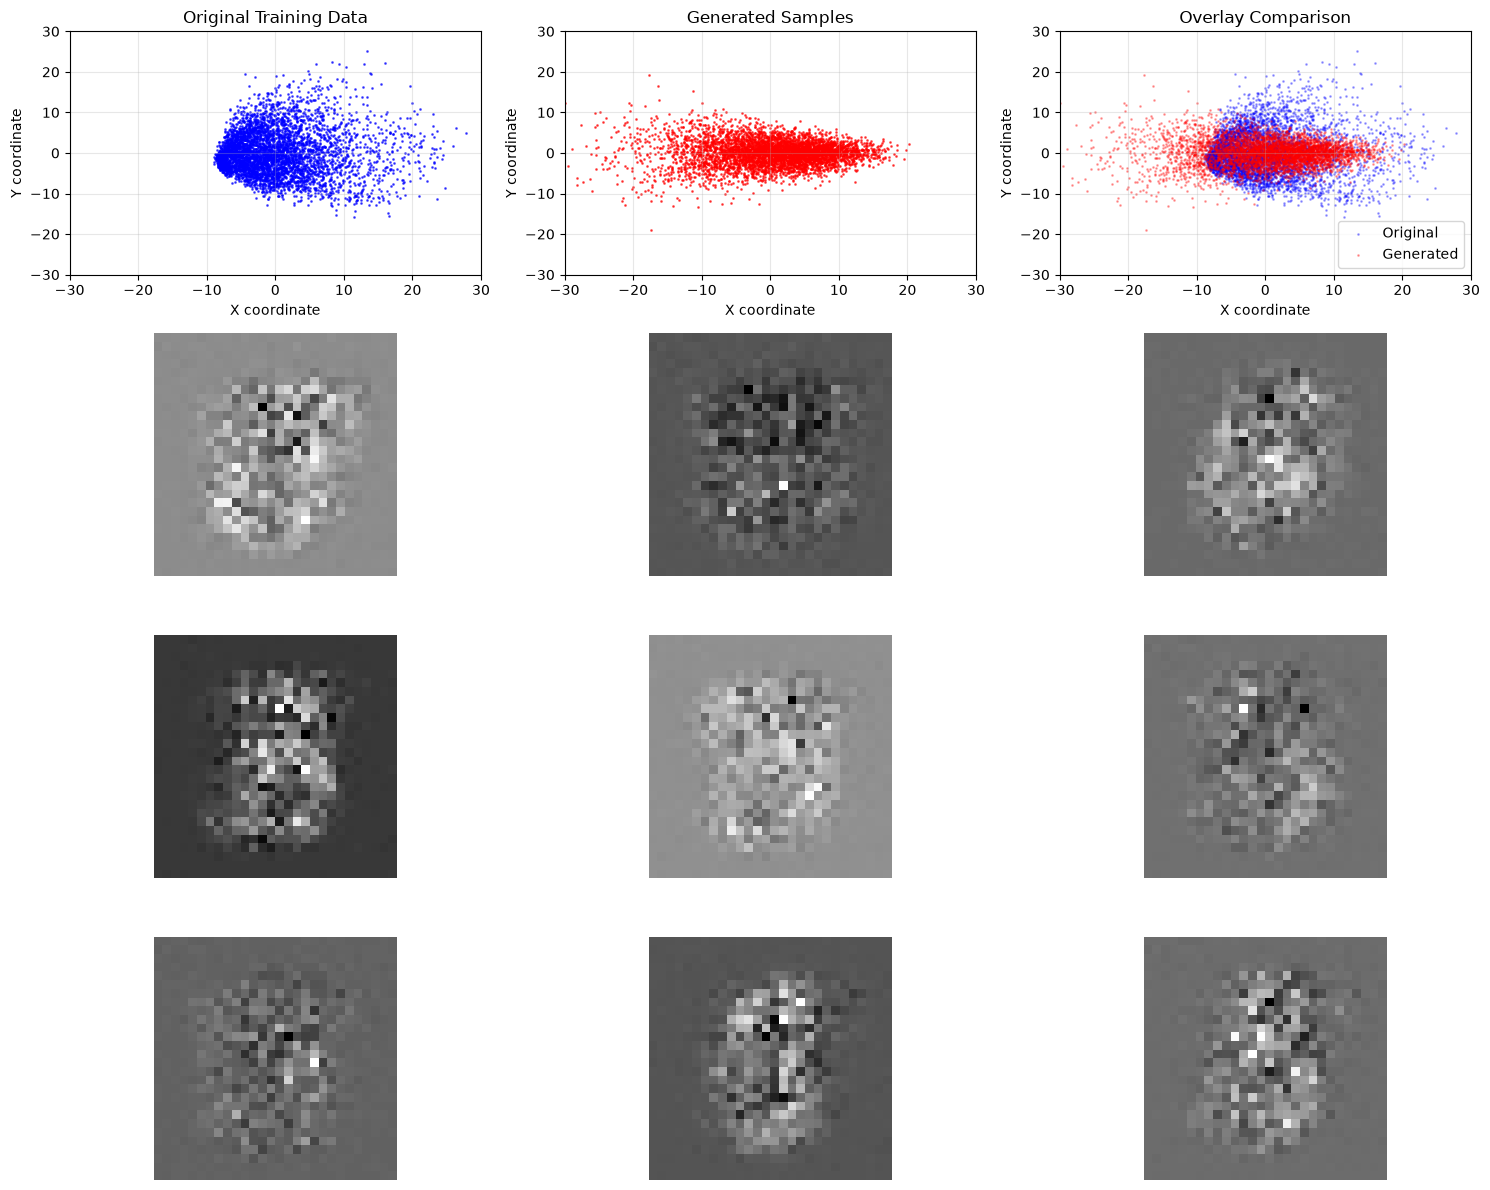

In [11]:
model.eval()  # Set to evaluation mode

with torch.no_grad():
    # Sample from our target Gaussian distribution
    z_samples = prior_z.sample((5000,))  # Generate 5000 samples
    
    # Transform back to moon distribution
    x_generated = model.backward(z_samples)
    
    # Convert to numpy for visualization
    z_samples = z_samples.cpu().numpy()
    x_generated = x_generated.cpu().numpy()

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(x_generated).transform(x_generated)

# Create comparison visualization
plt.figure(figsize=(15, 12))

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-30, 30)
plt.ylim(-30, 30)
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-30, 30)
plt.ylim(-30, 30)
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-30, 30)
plt.ylim(-30, 30)
plt.legend()
plt.grid(True, alpha=0.3)

for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(x_generated[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

